# **Telecom Customer Churn**

### Introduction

Customer churn is one of the major challenges faced by telecommunication companies. It refers to customers discontinuing the services of a company and switching to another provider or no longer using the service. A high churn rate can affect business growth, revenue, and customer retention.

The purpose of this project is to analyze telecom customer data and identify the factors and patterns associated with customer churn. Through Exploratory Data Analysis (EDA), we aim to understand why customers leave the company, which customer segments are more likely to churn, and how factors such as contract type, payment method, tenure, monthly charges, and additional services relate to customer retention.

By exploring these patterns, this project aims to generate meaningful business insights that can help the company understand customer behavior and develop better customer-retention strategies.

### Main Research Question

**"What factors are associated with customer churn in the telecommunications industry, and how can these factors help identify high-risk customers and improve customer retention?"**

#### Importing Libraries:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

#### Importing Dataset

In [2]:
pd.set_option('display.max_rows' , None)
pd.set_option('display.max_columns' , None)

df= pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#### **Column Summary**

##### 1. Customer Identification
| Column | Description |
|---|---|
| customerID | Unique identification number assigned to each customer. |

##### 2. Customer Demographics
| Column | Description |
|---|---|
| gender | Gender of the customer (Male/Female). |
| SeniorCitizen | Indicates whether the customer is a senior citizen (1 = Yes, 0 = No). |
| Partner | Indicates whether the customer has a partner. |
| Dependents | Indicates whether the customer has dependents. |

##### 3. Customer Account Information
| Column | Description |
|---|---|
| tenure | Number of months the customer has stayed with the company. |
| Contract | Type of customer contract (Month-to-month, One year, Two year). |
| PaperlessBilling | Indicates whether the customer receives paperless bills. |
| PaymentMethod | Method used by the customer to pay bills. |

##### 4. Customer Services
| Column | Description |
|---|---|
| PhoneService | Indicates whether the customer has phone service. |
| MultipleLines | Indicates whether the customer has multiple phone lines. |
| InternetService | Type of internet connection (DSL, Fiber optic, or No). |
| OnlineSecurity | Indicates whether the customer has online security service. |
| OnlineBackup | Indicates whether the customer has online backup service. |
| DeviceProtection | Indicates whether the customer has device protection service. |
| TechSupport | Indicates whether the customer has technical support service. |
| StreamingTV | Indicates whether the customer uses TV streaming services. |
| StreamingMovies | Indicates whether the customer uses movie streaming services. |

##### 5. Financial Information
| Column | Description |
|---|---|
| MonthlyCharges | Amount charged to the customer every month. |
| TotalCharges | Total amount charged during the customer's subscription. |

##### 6. Target Variable
| Column | Description |
|---|---|
| Churn | Indicates whether the customer has left the company (Yes/No). |

#### Exploring the Dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df.shape

(7043, 21)

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [8]:
df['TotalCharges'].unique()

array(['29.85', '1889.5', '108.15', ..., '346.45', '306.6', '6844.5'],
      shape=(6531,), dtype=object)

In [9]:
df['TotalCharges'].dtype

dtype('O')

In [10]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


In [11]:
df['TotalCharges'].dtype

dtype('float64')

#### Finding Null Values

In [12]:
df.isna().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [13]:
df.isna().sum().sum()

np.int64(11)

Here we have 11 missing values in 'TotalCharges' column.

In [14]:
df['TotalCharges'].describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

In [15]:
df.loc[(df['TotalCharges'].isna()) & (df['tenure'] == 0),'TotalCharges'] = 0

In [16]:
df['TotalCharges'].isna().sum()

np.int64(0)

The TotalCharges column contains 11 missing values. Upon investigation, these missing values correspond to customers with zero tenure. Since these customers have just joined the company and have no accumulated service charges, their missing TotalCharges values are replaced with zero instead of using mean imputation.

In [17]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

#### Finding Duplicate

In [18]:
df.duplicated().sum()

np.int64(0)

In the given dataset the CustomerID is not useful because it has so many unique values. so we will drop the column.

In [19]:
df.drop('customerID' , axis= 1 , inplace= True)

## ***Insights of the Data***

### **Q1: Does customer gender have any significant relationship with churn?**

In [20]:
df['gender'].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

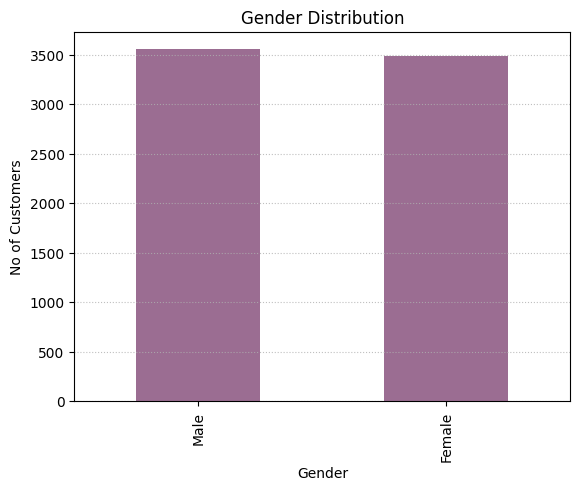

In [21]:
df['gender'].value_counts().plot(kind='bar' , color="#864E7BD2")
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('No of Customers')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)
plt.show

In [22]:
pd.crosstab(df['Churn'],df['gender'])

gender,Female,Male
Churn,,
No,2549,2625
Yes,939,930


In [23]:
pd.crosstab(df['Churn'],df['gender'],normalize='index')*100

gender,Female,Male
Churn,,
No,49.265559,50.734441
Yes,50.240770,49.759230


<function matplotlib.pyplot.show(close=None, block=None)>

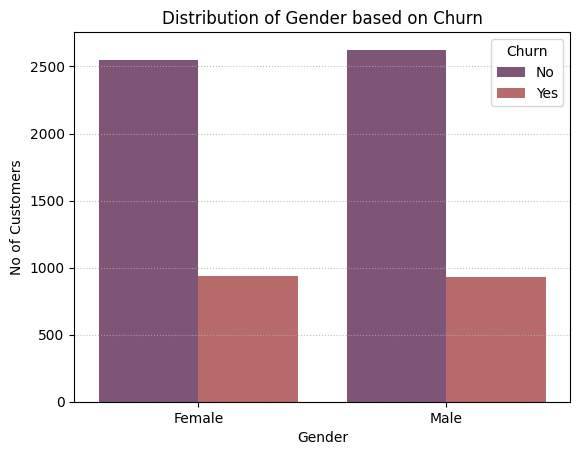

In [24]:
sns.countplot(df, x='gender' , hue= 'Churn', palette=["#864E7BD2", "#C55E5E"])
plt.title('Distribution of Gender based on Churn')
plt.xlabel('Gender')
plt.ylabel('No of Customers')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)
plt.show

in the given plot we can see that we have 3480 Females and 3541 Males, in Females 2546 are not churn while 934 are churn, and in Males 2618 are not churn while 923 Males are not availing the serice anymore and are churn customers. According to the given graph both male and female are approximately equally churn which is not showing any deeper impact of any specific gender Churn Customer.

#### **Q2: Does customer churn behaviour differ between male and female customers across contract types, tenure groups, and additional service subscriptions?**

In [25]:
pd.crosstab([df['gender'] , df['DeviceProtection']],[df['Churn']],normalize='index')*100

Churn                              No        Yes
gender DeviceProtection                         
Female No                   59.947984  40.052016
       No internet service  92.503347   7.496653
       Yes                  77.805486  22.194514
Male   No                   61.785485  38.214515
       No internet service  92.682927   7.317073
       Yes                  77.194422  22.805578

In [26]:
pd.crosstab([df['gender'] , df['OnlineBackup']], df['Churn'],normalize='index')*100

Churn                              No        Yes
gender OnlineBackup                             
Female No                   59.207921  40.792079
       No internet service  92.503347   7.496653
       Yes                  78.384992  21.615008
Male   No                   60.902734  39.097266
       No internet service  92.682927   7.317073
       Yes                  78.553616  21.446384

In [27]:
pd.crosstab([df['gender'] , df['OnlineSecurity']], df['Churn'] , normalize='index')*100

Churn                              No        Yes
gender OnlineSecurity                           
Female No                   57.934656  42.065344
       No internet service  92.503347   7.496653
       Yes                  84.225901  15.774099
Male   No                   58.520179  41.479821
       No internet service  92.682927   7.317073
       Yes                  86.592742  13.407258

In [28]:
pd.crosstab([df['gender'] , df['TechSupport']], df['Churn'], normalize='index')*100

Churn                              No        Yes
gender TechSupport                              
Female No                   58.109685  41.890315
       No internet service  92.503347   7.496653
       Yes                  83.933788  16.066212
Male   No                   58.612848  41.387152
       No internet service  92.682927   7.317073
       Yes                  85.742380  14.257620

In [29]:
pd.crosstab([df['gender'] , df['Contract']], df['Churn'], normalize='index')*100

Churn                         No        Yes
gender Contract                            
Female Month-to-month  56.259740  43.740260
       One year        89.554318  10.445682
       Two year        97.396450   2.603550
Male   Month-to-month  58.307692  41.692308
       One year        87.947020  12.052980
       Two year        96.941176   3.058824

In [30]:
pd.crosstab([df['gender'] , pd.cut(df['tenure'] , bins=[-1 , 12, 24, 36 , 48 , 60 , 72])], df['Churn'], normalize='index')*100

Churn                   No        Yes
gender tenure                        
Female (-1, 12]  51.014760  48.985240
       (12, 24]  71.653543  28.346457
       (24, 36]  75.555556  24.444444
       (36, 48]  80.000000  20.000000
       (48, 60]  88.249400  11.750600
       (60, 72]  94.658754   5.341246
Male   (-1, 12]  54.083485  45.916515
       (12, 24]  70.930233  29.069767
       (24, 36]  81.030445  18.969555
       (36, 48]  82.044199  17.955801
       (48, 60]  82.891566  17.108434
       (60, 72]  92.223738   7.776262

The gender-based analysis reveals that customer churn is more closely associated with contract type, tenure, and additional service subscriptions than with gender alone.

Month-to-month customers and customers within their first 12 months demonstrate the highest churn rates across both genders. Furthermore, customers who do not subscribe to Device Protection, Online Backup, Online Security, and Tech Support consistently show higher churn rates than those who subscribe to these services.

Among the additional services, Online Security and Tech Support demonstrate particularly noticeable differences in churn. Meanwhile, male and female customers exhibit broadly similar patterns across all six analyses, indicating that gender does not appear to be the dominant factor in customer churn.

#### **Q3: Are senior citizens more likely to churn than non-senior citizens?**

In [31]:
df['SeniorCitizen'].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

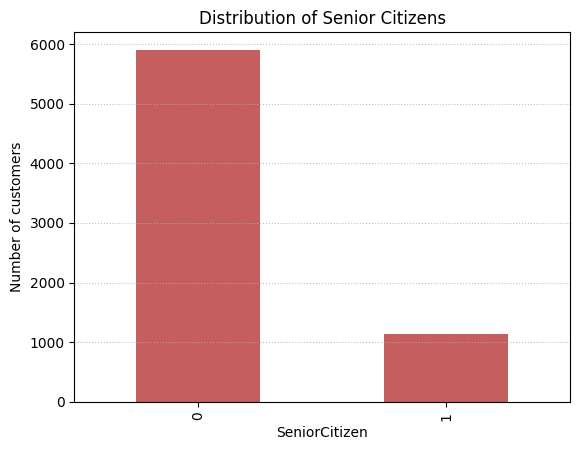

In [32]:
df['SeniorCitizen'].value_counts().plot(kind='bar' , color="#C55E5E")
plt.title('Distribution of Senior Citizens')
plt.xlabel('SeniorCitizen')
plt.ylabel('Number of customers')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)
plt.show

In [33]:
pd.crosstab(df['SeniorCitizen'] , df['Churn'])

Churn,No,Yes
SeniorCitizen,,
0,4508,1393
1,666,476


In [34]:
pd.crosstab(df['SeniorCitizen'] , df['Churn'] , normalize='index')*100

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


<function matplotlib.pyplot.show(close=None, block=None)>

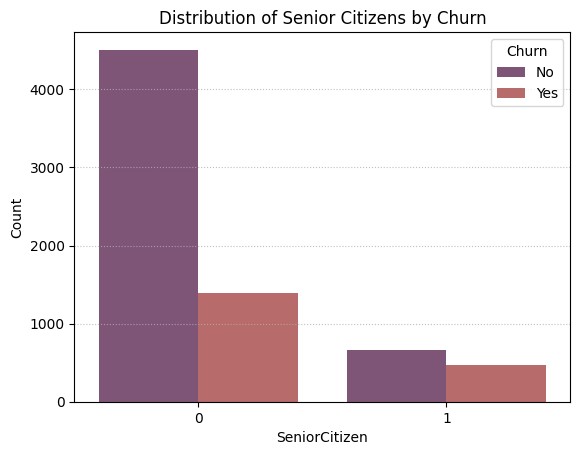

In [35]:
sns.countplot(df , x='SeniorCitizen' , hue='Churn' , palette=["#864E7BD2", "#C55E5E"])
plt.title('Distribution of Senior Citizens by Churn')
plt.xlabel('SeniorCitizen')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)
plt.show

The analysis reveals that senior citizens are more likely to churn than non-senior customers. Senior citizens demonstrate a churn rate of 41.63%, compared with 23.50% among non-senior customers. This indicates a noticeable association between senior citizen status and customer churn. The company should further investigate the needs and service experiences of senior customers to identify opportunities for improving retention.

#### **Q4: Does customer churn behaviour differ between senior and non-senior customers across service subscriptions, contract types, payment methods, dependents, internet services, and tenure?**

In [36]:
pd.crosstab([df['SeniorCitizen'] , df['OnlineSecurity']], df['Churn'], normalize='index')*100

Churn                                     No        Yes
SeniorCitizen OnlineSecurity                           
0             No                   60.817844  39.182156
              No internet service  92.672999   7.327001
              Yes                  86.701209  13.298791
1             No                   49.628713  50.371287
              No internet service  90.384615   9.615385
              Yes                  77.304965  22.695035

In [37]:
pd.crosstab([df['SeniorCitizen'] , df['OnlineBackup']],df['Churn'], normalize='index') * 100

Churn                                     No        Yes
SeniorCitizen OnlineBackup                             
0             No                   63.257882  36.742118
              No internet service  92.672999   7.327001
              Yes                  80.747568  19.252432
1             No                   47.231270  52.768730
              No internet service  90.384615   9.615385
              Yes                  69.117647  30.882353

In [38]:
pd.crosstab([df['SeniorCitizen'] , df['DeviceProtection']],df['Churn'] , normalize='index') * 100

Churn                                     No        Yes
SeniorCitizen DeviceProtection                         
0             No                   63.941724  36.058276
              No internet service  92.672999   7.327001
              Yes                  79.856851  20.143149
1             No                   48.717949  51.282051
              No internet service  90.384615   9.615385
              Yes                  67.596567  32.403433

In [39]:
pd.crosstab([df['SeniorCitizen'] , df['TechSupport']],df['Churn'],normalize='index')*100

Churn                                     No        Yes
SeniorCitizen TechSupport                              
0             No                   61.180477  38.819523
              No internet service  92.672999   7.327001
              Yes                  85.482063  14.517937
1             No                   49.397590  50.602410
              No internet service  90.384615   9.615385
              Yes                  80.384615  19.615385

In [40]:
pd.crosstab([df['SeniorCitizen'] , df['Contract']],df['Churn'],normalize='index')*100

Churn                                No        Yes
SeniorCitizen Contract                            
0             Month-to-month  60.430248  39.569752
              One year        89.321902  10.678098
              Two year        97.290323   2.709677
1             Month-to-month  45.353160  54.646840
              One year        84.736842  15.263158
              Two year        95.862069   4.137931

In [41]:
pd.crosstab([df['SeniorCitizen'] , df['PaymentMethod']],df['Churn'],normalize='index')*100

Churn                                           No        Yes
SeniorCitizen PaymentMethod                                  
0             Bank transfer (automatic)  84.363082  15.636918
              Credit card (automatic)    86.933128  13.066872
              Electronic check           57.425184  42.574816
              Mailed check               82.608696  17.391304
1             Bank transfer (automatic)  77.253219  22.746781
              Credit card (automatic)    71.945701  28.054299
              Electronic check           46.632997  53.367003
              Mailed check               53.191489  46.808511

In [42]:
pd.crosstab([df['SeniorCitizen'] , df['Dependents']],df['Churn'],normalize='index')*100

Churn                            No        Yes
SeniorCitizen Dependents                      
0             No          71.947450  28.052550
              Yes         84.943041  15.056959
1             No          56.803045  43.196955
              Yes         75.824176  24.175824

In [43]:
pd.crosstab([df['SeniorCitizen'] , df['InternetService']],df['Churn'],normalize='index')*100

Churn                                 No        Yes
SeniorCitizen InternetService                      
0             DSL              82.377428  17.622572
              Fiber optic      60.088300  39.911700
              No               92.672999   7.327001
1             DSL              69.884170  30.115830
              Fiber optic      52.707581  47.292419
              No               90.384615   9.615385

In [44]:
pd.crosstab([df['SeniorCitizen'] , pd.cut(df['tenure'] , bins=[-1 , 12, 24, 36 , 48 , 60 , 72])],df['Churn'],normalize='index')*100

Churn                          No        Yes
SeniorCitizen tenure                        
0             (-1, 12]  56.055734  43.944266
              (12, 24]  75.350467  24.649533
              (24, 36]  82.789318  17.210682
              (36, 48]  85.446009  14.553991
              (48, 60]  87.737226  12.262774
              (60, 72]  94.157494   5.842506
1             (-1, 12]  32.187500  67.812500
              (12, 24]  50.595238  49.404762
              (24, 36]  59.493671  40.506329
              (36, 48]  57.723577  42.276423
              (48, 60]  75.510204  24.489796
              (60, 72]  89.380531  10.619469

The analysis reveals that senior citizen status is associated with higher customer churn across almost every dimension examined. Senior customers consistently demonstrate higher churn than non-senior customers across additional service subscriptions, contract types, payment methods, dependent status, internet service types, and tenure groups.

The most concerning segments include:
- Senior customers with month-to-month contracts: 54.59% churn.
- Senior customers using electronic checks: 53.29% churn.
- Senior customers without Online Backup: 52.69% churn.
- Senior customers without Device Protection: 51.20% churn.
- Senior customers without Online Security: 50.31% churn.
- Senior customers in their first 12 months: 67.71% churn.  

These findings suggest that senior customers, particularly those with shorter tenure, month-to-month contracts, electronic check payments, and fewer additional services, deserve closer attention in customer retention analysis.

#### **Q5: Do customers with partners or dependents demonstrate better retention than customers without partners or dependents?**

In [45]:
df['Dependents'].value_counts()

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

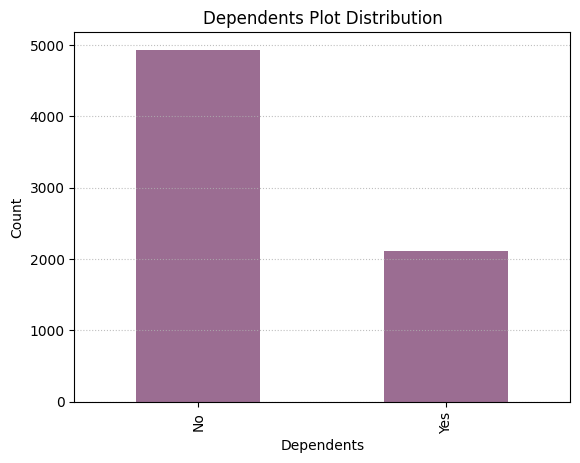

In [46]:
df['Dependents'].value_counts().plot(kind='bar' , color="#864E7BD2")
plt.title('Dependents Plot Distribution')
plt.xlabel('Dependents')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)
plt.show()

In [47]:
df['Partner'].value_counts()

Partner
No     3641
Yes    3402
Name: count, dtype: int64

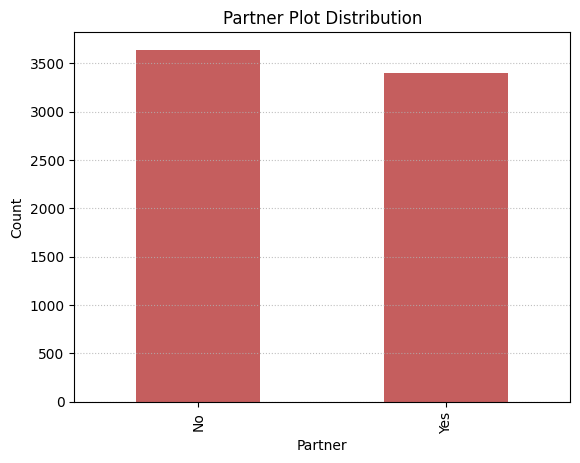

In [48]:
df['Partner'].value_counts().plot(kind='bar' , color= "#C55E5E" )
plt.title('Partner Plot Distribution')
plt.xlabel('Partner')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)

In [49]:
pd.crosstab(df['Dependents'], df['Churn'], normalize='index') * 100


Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


In [50]:
pd.crosstab(df['Partner'], df['Churn'], normalize='index') * 100

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


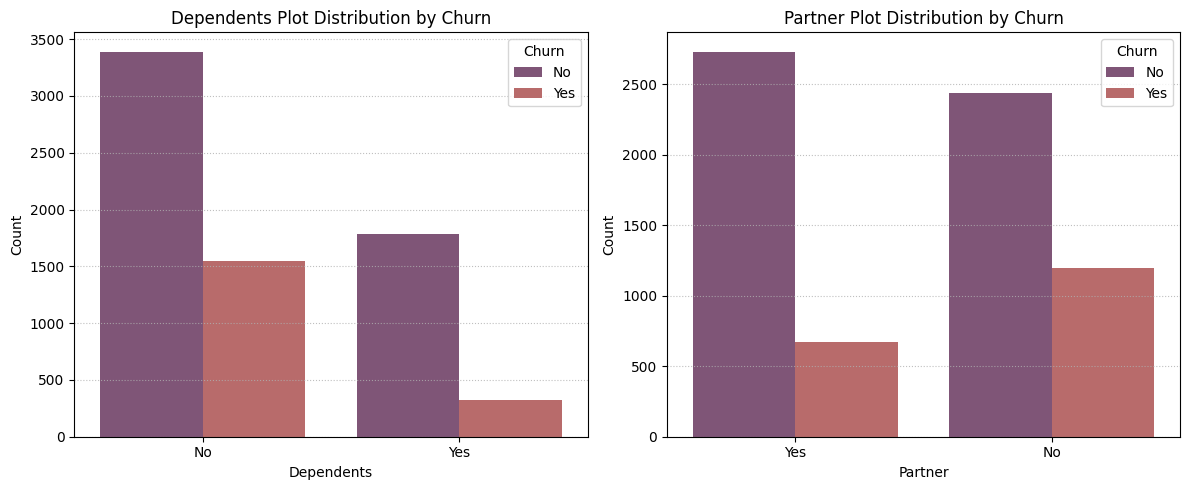

In [51]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.countplot(data=df, x='Dependents', hue='Churn', palette=["#864E7BD2", "#C55E5E"])
plt.title('Dependents Plot Distribution by Churn')
plt.xlabel('Dependents')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)

plt.subplot(1,2,2)
sns.countplot(data=df, x='Partner', hue='Churn', palette=["#864E7BD2", "#C55E5E"])
plt.title('Partner Plot Distribution by Churn')
plt.xlabel('Partner')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)

plt.tight_layout()
plt.show()

The analysis shows that customers without dependents have a higher number of churn cases compared to customers with dependents. Similarly, customers without a partner show more churn cases than customers with a partner. This suggests that customers with dependents or partners may be more likely to remain with the company, while customers without dependents or partners may have a higher tendency to leave.

#### **Q6: How does customer churn vary among customers with and without partners or dependents across service subscriptions, contract types, internet services, and tenure?**

##### 1. Dependents

In [52]:
pd.crosstab([df['Dependents'] , df['DeviceProtection']], df['Churn'], normalize='index')*100

Churn                                  No        Yes
Dependents DeviceProtection                         
No         No                   56.968421  43.031579
           No internet service  90.373726   9.626274
           Yes                  73.970149  26.029851
Yes        No                   73.750000  26.250000
           No internet service  95.645412   4.354588
           Yes                  85.408300  14.591700

In [53]:
pd.crosstab([df['Dependents'] , df['OnlineBackup']] , df['Churn'], normalize='index')*100

Churn                                  No        Yes
Dependents OnlineBackup                             
No         No                   56.561845  43.438155
           No internet service  90.373726   9.626274
           Yes                  74.654655  25.345345
Yes        No                   71.977240  28.022760
           No internet service  95.645412   4.354588
           Yes                  86.780105  13.219895

In [54]:
pd.crosstab([df['Dependents'] ,df['OnlineSecurity'] ], df['Churn'], normalize='index')*100

Churn                                  No        Yes
Dependents OnlineSecurity                           
No         No                   55.265069  44.734931
           No internet service  90.373726   9.626274
           Yes                  82.561728  17.438272
Yes        No                   69.220430  30.779570
           No internet service  95.645412   4.354588
           Yes                  90.456432   9.543568

In [55]:
pd.crosstab([df['Dependents'] ,df['TechSupport']], df['Churn'], normalize='index')*100

Churn                                  No        Yes
Dependents TechSupport                              
No         No                   54.998156  45.001844
           No internet service  90.373726   9.626274
           Yes                  82.225541  17.774459
Yes        No                   70.341207  29.658793
           No internet service  95.645412   4.354588
           Yes                  89.787234  10.212766

In [56]:
pd.crosstab([df['Dependents'] ,df['Contract']], df['Churn'], normalize='index')*100

Churn                             No        Yes
Dependents Contract                            
No         Month-to-month  54.763448  45.236552
           One year        87.579618  12.420382
           Two year        96.685083   3.314917
Yes        Month-to-month  67.173638  32.826362
           One year        90.772128   9.227872
           Two year        97.721519   2.278481

In [57]:
pd.crosstab([df['Dependents'] ,df['InternetService']], df['Churn'], normalize='index')*100

Churn                              No        Yes
Dependents InternetService                      
No         DSL              77.537129  22.462871
           Fiber optic      55.012325  44.987675
           No               90.373726   9.626274
Yes        DSL              88.074534  11.925466
           Fiber optic      69.486405  30.513595
           No               95.645412   4.354588

In [58]:
pd.crosstab([df['Dependents'] ,pd.cut(df['tenure'], bins=[-1,12,24,36,48,60,72])], df['Churn'], normalize='index')*100

Churn                       No        Yes
Dependents tenure                        
No         (-1, 12]  48.966705  51.033295
           (12, 24]  67.083333  32.916667
           (24, 36]  75.783972  24.216028
           (36, 48]  77.103718  22.896282
           (48, 60]  82.214156  17.785844
           (60, 72]  92.455090   7.544910
Yes        (-1, 12]  66.666667  33.333333
           (12, 24]  81.250000  18.750000
           (24, 36]  84.108527  15.891473
           (36, 48]  88.844622  11.155378
           (48, 60]  92.170819   7.829181
           (60, 72]  94.755245   5.244755

Customers without dependents consistently show higher churn across all seven analyses. Month-to-month contracts, Fiber optic services, and the absence of additional services such as Online Security and Tech Support are also associated with higher churn. Furthermore, newer customers are more likely to leave, while long-term customers show better retention.

Overall, customers without dependents and those on month-to-month contracts represent important segments for customer retention strategies.

##### 2. Partner

In [59]:
pd.crosstab([df['Partner'] , df['DeviceProtection']], df['Churn'], normalize='index')*100

Churn                               No        Yes
Partner DeviceProtection                         
No      No                   55.113025  44.886975
        No internet service  89.340102  10.659898
        Yes                  71.658291  28.341709
Yes     No                   69.523040  30.476960
        No internet service  96.070461   3.929539
        Yes                  81.569727  18.430273

In [60]:
pd.crosstab([df['Partner'] , df['OnlineBackup']] , df['Churn'], normalize='index')*100

Churn                               No        Yes
Partner OnlineBackup                             
No      No                   54.743730  45.256270
        No internet service  89.340102  10.659898
        Yes                  71.933268  28.066732
Yes     No                   67.862839  32.137161
        No internet service  96.070461   3.929539
        Yes                  83.191489  16.808511

In [61]:
pd.crosstab([df['Partner'] ,df['OnlineSecurity'] ], df['Churn'], normalize='index')*100

Churn                               No        Yes
Partner OnlineSecurity                           
No      No                   52.871870  47.128130
        No internet service  89.340102  10.659898
        Yes                  80.882353  19.117647
Yes     No                   65.708419  34.291581
        No internet service  96.070461   3.929539
        Yes                  88.445553  11.554447

In [62]:
pd.crosstab([df['Partner'] ,df['TechSupport'] ], df['Churn'], normalize='index')*100

Churn                               No        Yes
Partner TechSupport                              
No      No                   52.565392  47.434608
        No internet service  89.340102  10.659898
        Yes                  80.000000  20.000000
Yes     No                   66.127946  33.872054
        No internet service  96.070461   3.929539
        Yes                  88.379983  11.620017

In [63]:
pd.crosstab([df['Partner'] ,df['InternetService'] ], df['Churn'], normalize='index')*100

Churn                           No        Yes
Partner InternetService                      
No      DSL              74.381484  25.618516
        Fiber optic      50.312500  49.687500
        No               89.340102  10.659898
Yes     DSL              88.184932  11.815068
        Fiber optic      66.443850  33.556150
        No               96.070461   3.929539

In [64]:
pd.crosstab([df['Partner'] ,df['Contract'] ], df['Churn'], normalize='index')*100

Churn                          No        Yes
Partner Contract                            
No      Month-to-month  55.310621  44.689379
        One year        89.424572  10.575428
        Two year        96.620278   3.379722
Yes     Month-to-month  60.869565  39.130435
        One year        88.192771  11.807229
        Two year        97.399329   2.600671

In [65]:
pd.crosstab([df['Partner'] ,pd.cut(df['tenure'], bins=[-1,12,24,36,48,60,72])], df['Churn'], normalize='index')*100

Churn                    No        Yes
Partner tenure                        
No      (-1, 12]  51.139864  48.860136
        (12, 24]  70.338983  29.661017
        (24, 36]  78.688525  21.311475
        (36, 48]  79.775281  20.224719
        (48, 60]  85.852090  14.147910
        (60, 72]  92.514970   7.485030
Yes     (-1, 12]  56.660746  43.339254
        (12, 24]  72.580645  27.419355
        (24, 36]  78.024691  21.975309
        (36, 48]  82.019704  17.980296
        (48, 60]  85.412668  14.587332
        (60, 72]  93.662628   6.337372

Customers without partners generally show higher churn across services, internet types, and tenure groups. Online Security and Tech Support subscriptions are associated with lower churn, while Fiber optic and month-to-month customers show higher churn. However, partner status does not show a consistent relationship with churn across every contract category.

Overall, customers without partners, particularly those using month-to-month contracts or lacking additional services, represent important segments for further retention analysis.

#### **Q7: Does having multiple phone lines influence customer churn?**

In [66]:
df['MultipleLines'].value_counts()

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

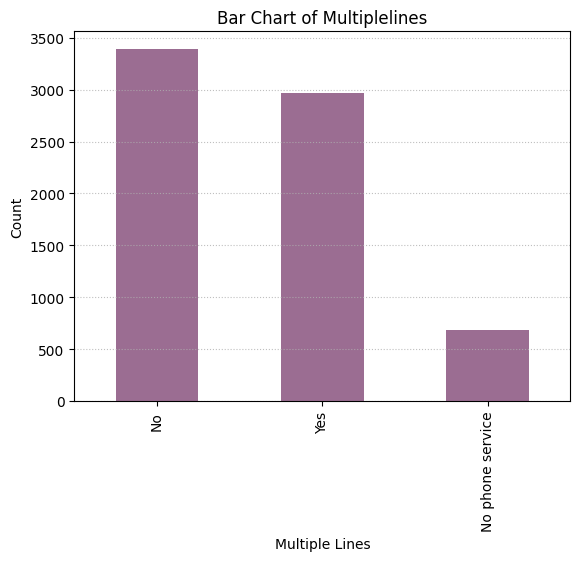

In [67]:
df['MultipleLines'].value_counts().plot(kind='bar' , color="#864E7BD2")
plt.title('Bar Chart of Multiplelines')
plt.xlabel('Multiple Lines')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)
plt.show


In [68]:
pd.crosstab(df['MultipleLines'] , df['Churn'], normalize='index')*100

Churn,No,Yes
MultipleLines,,
No,74.955752,25.044248
No phone service,75.073314,24.926686
Yes,71.390104,28.609896


<function matplotlib.pyplot.show(close=None, block=None)>

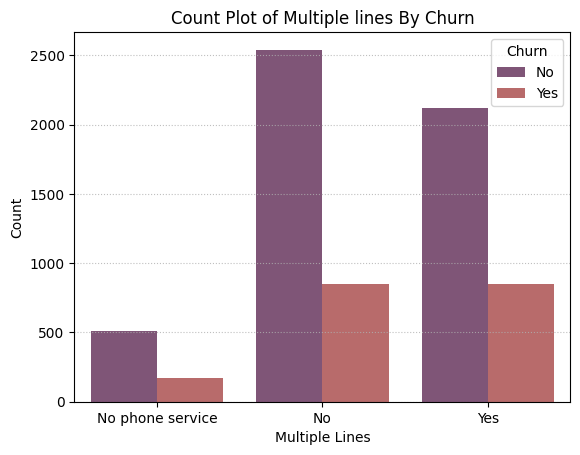

In [69]:
sns.countplot(df , x='MultipleLines', hue='Churn' ,  palette=["#864E7BD2", "#C55E5E"])
plt.title('Count Plot of Multiple lines By Churn')
plt.xlabel('Multiple Lines')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)
plt.show

The analysis shows that 837 customers without multiple phone lines churned, while 2,531 customers stayed with the company. Among customers with multiple phone lines, 850 customers churned, while 2,121 customers remained with the company. Additionally, 170 customers without phone service churned, while 512 remained. Overall, the number of churned customers is quite similar between customers with and without multiple phone lines, suggesting that MultipleLines alone may not have a major impact on customer churn.

#### **Q8: Which internet service category experiences the highest customer churn, and are additional service subscriptions associated with different churn patterns within each category?**

In [70]:
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

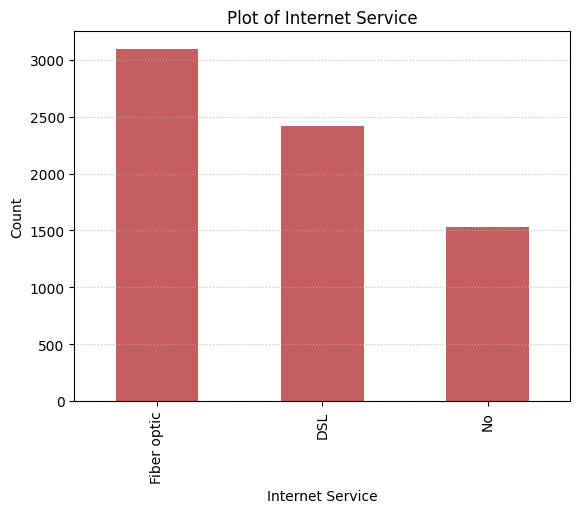

In [71]:
df['InternetService'].value_counts().plot(kind='bar' , color="#C55E5E" )
plt.title('Plot of Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)
plt.show

In [72]:
pd.crosstab(df['InternetService'] , df['Churn'],normalize='index')*100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


<function matplotlib.pyplot.show(close=None, block=None)>

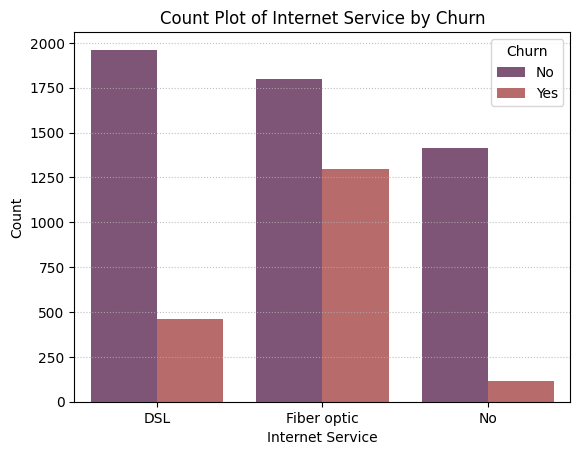

In [73]:
sns.countplot(df , x='InternetService', hue='Churn' ,  palette=["#864E7BD2", "#C55E5E"])
plt.title('Count Plot of Internet Service by Churn')
plt.xlabel('Internet Service')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle=':' , alpha = 0.8)
plt.show

In internet service Fiber Optics users are 3090 and in 3090, 1799 are not churn while 1291 are churn . In DSL 2419 are using the service while, 1962 are not churn and 457 are churn. And 1512 are not using any internet service in which 1413 are not churn and 109 are churn .

#### **Q9: Are Fiber Optic customers without additional internet services more likely to churn than customers who subscribe to these services?**

In [74]:
pd.crosstab((df['InternetService'] =='Fiber optic') , df['Churn'], normalize='index')*100

Churn,No,Yes
InternetService,,
False,85.507981,14.492019
True,58.107235,41.892765


In [75]:
fiber_df = df[df['InternetService'] == 'Fiber optic']

In [76]:
print(fiber_df['InternetService'].unique())

['Fiber optic']


In [77]:
services = ['OnlineBackup', 'OnlineSecurity',
            'DeviceProtection', 'TechSupport']

for service in services:
    print(f"\n{service}:")
    result = pd.crosstab(
        fiber_df[service],
        fiber_df['Churn'],
        normalize='index'
    ) * 100

    print(result.round(2))


OnlineBackup:
Churn            No    Yes
OnlineBackup              
No            49.23  50.77
Yes           69.69  30.31

OnlineSecurity:
Churn              No    Yes
OnlineSecurity              
No              50.64  49.36
Yes             78.19  21.81

DeviceProtection:
Churn                No    Yes
DeviceProtection              
No                50.03  49.97
Yes               68.46  31.54

TechSupport:
Churn           No    Yes
TechSupport              
No           50.63  49.37
Yes          77.37  22.63


 #Key Insight
- Online Security shows the largest churn-rate difference (27.41 percentage points).
- Tech Support shows the second-largest difference (26.61 percentage points).
- Online Backup follows with 20.29 percentage points.
- Device Protection shows an 18.26 percentage-point difference.
Final Conclusion:

The analysis reveals that Fiber Optic customers who do not subscribe to additional services, particularly Online Security and Tech Support, have considerably higher churn rates. This suggests that the availability and adoption of these services may be associated with customer retention. The company should investigate whether improving these service offerings could help reduce customer churn.

#### **Q10: Among Fiber Optic customers, how are contract type, dependents, tenure, and payment method associated with customer churn?**

In [78]:
pd.crosstab([fiber_df['InternetService'] , fiber_df['Contract']],fiber_df['Churn'], normalize='index')*100

Churn                                  No        Yes
InternetService Contract                            
Fiber optic     Month-to-month  45.394737  54.605263
                One year        80.705009  19.294991
                Two year        92.773893   7.226107

In [79]:
pd.crosstab([fiber_df['InternetService'] , fiber_df['Dependents']],fiber_df['Churn'], normalize='index')*100

Churn                              No        Yes
InternetService Dependents                      
Fiber optic     No          55.012325  44.987675
                Yes         69.486405  30.513595

In [80]:
pd.crosstab([fiber_df['InternetService'] , pd.cut(fiber_df['tenure'], bins=[-1, 12, 24, 36, 48, 60, 72])],fiber_df['Churn'], normalize='index')*100

Churn                            No        Yes
InternetService tenure                        
Fiber optic     (-1, 12]  30.119177  69.880823
                (12, 24]  51.224944  48.775056
                (24, 36]  60.367454  39.632546
                (36, 48]  66.869301  33.130699
                (48, 60]  75.388601  24.611399
                (60, 72]  87.579618  12.420382

In [81]:
pd.crosstab([fiber_df['InternetService'] , fiber_df['PaymentMethod']],fiber_df['Churn'], normalize='index')*100

Churn                                             No        Yes
InternetService PaymentMethod                                  
Fiber optic     Bank transfer (automatic)  71.052632  28.947368
                Credit card (automatic)    74.706868  25.293132
                Electronic check           46.771160  53.228840
                Mailed check               57.364341  42.635659

In [82]:
pd.crosstab(
    [fiber_df['InternetService'],
    fiber_df['Contract']],
    fiber_df['PaymentMethod'],
    normalize='index'
)*100

PaymentMethod                   Bank transfer (automatic)  \
InternetService Contract                                    
Fiber optic     Month-to-month                  15.366541   
                One year                        29.128015   
                Two year                        37.762238   

PaymentMethod                   Credit card (automatic)  Electronic check  \
InternetService Contract                                                    
Fiber optic     Month-to-month                13.768797         61.419173   
                One year                      27.829314         36.363636   
                Two year                      35.897436         21.445221   

PaymentMethod                   Mailed check  
InternetService Contract                      
Fiber optic     Month-to-month      9.445489  
                One year            6.679035  
                Two year            4.895105

The Fiber Optic analysis reveals several customer segments associated with higher churn. Customers with month-to-month contracts, shorter tenure, no dependents, and Electronic Check payments demonstrate comparatively higher churn rates. These patterns suggest that contract type, customer tenure, dependent status, and payment method are important factors to consider when investigating Fiber Optic customer retention.

#### **Q11: How does the subscription status of the four additional services relate to customer churn?**

In [83]:
df['OnlineBackup'].value_counts()

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

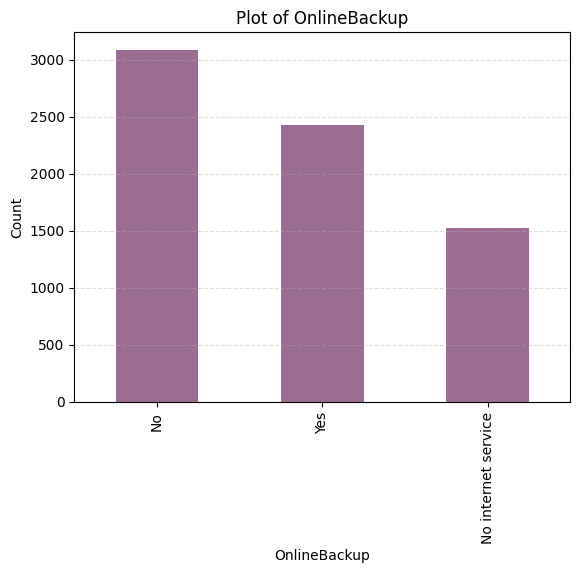

In [84]:
df['OnlineBackup'].value_counts().plot(kind='bar' , color="#864E7BD2")
plt.title('Plot of OnlineBackup')
plt.xlabel('OnlineBackup')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show

In [85]:
pd.crosstab(df['OnlineBackup'],df['Churn'],normalize='index') * 100

Churn,No,Yes
OnlineBackup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


In [86]:
df['OnlineSecurity'].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

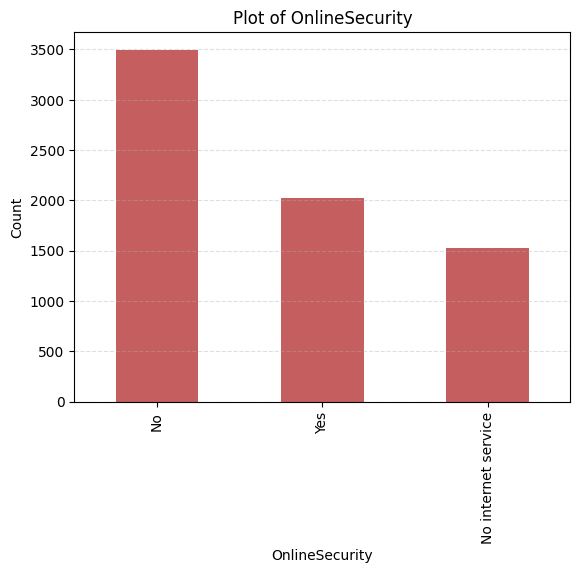

In [87]:
df['OnlineSecurity'].value_counts().plot(kind='bar' , color="#C55E5E")
plt.title('Plot of OnlineSecurity')
plt.xlabel('OnlineSecurity')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show


In [88]:
pd.crosstab(df['OnlineSecurity'],df['Churn'],normalize='index') * 100

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


In [89]:
df['DeviceProtection'].value_counts()

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

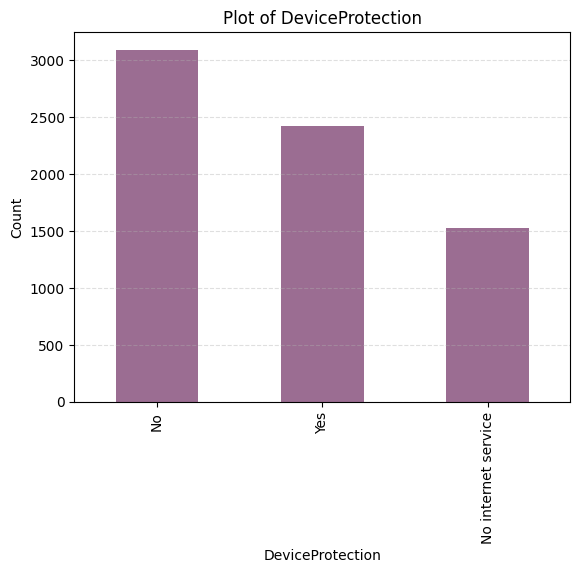

In [90]:
df['DeviceProtection'].value_counts().plot(kind='bar' , color= "#864E7BD2")
plt.title('Plot of DeviceProtection')
plt.xlabel('DeviceProtection')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show


In [91]:
pd.crosstab(df['DeviceProtection'],df['Churn'],normalize='index') * 100

Churn,No,Yes
DeviceProtection,,
No,60.872375,39.127625
No internet service,92.595020,7.404980
Yes,77.497936,22.502064


In [92]:
df['TechSupport'].value_counts()

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

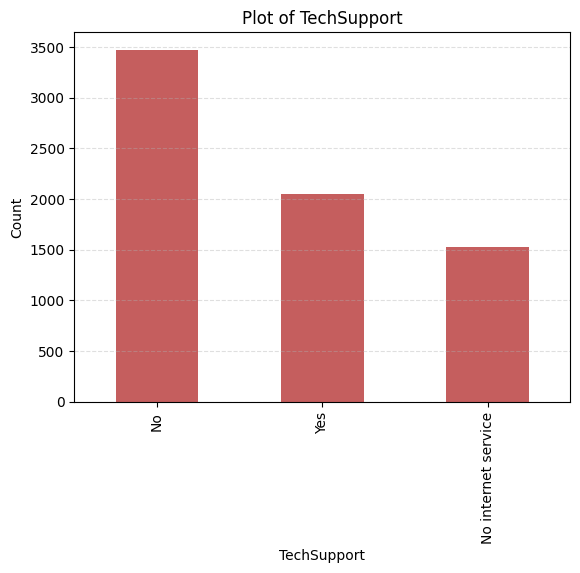

In [93]:
df['TechSupport'].value_counts().plot(kind='bar' , color= "#C55E5E")
plt.title('Plot of TechSupport')
plt.xlabel('TechSupport')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show


In [94]:
pd.crosstab(df['TechSupport'],df['Churn'],normalize='index') * 100

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


<function matplotlib.pyplot.show(close=None, block=None)>

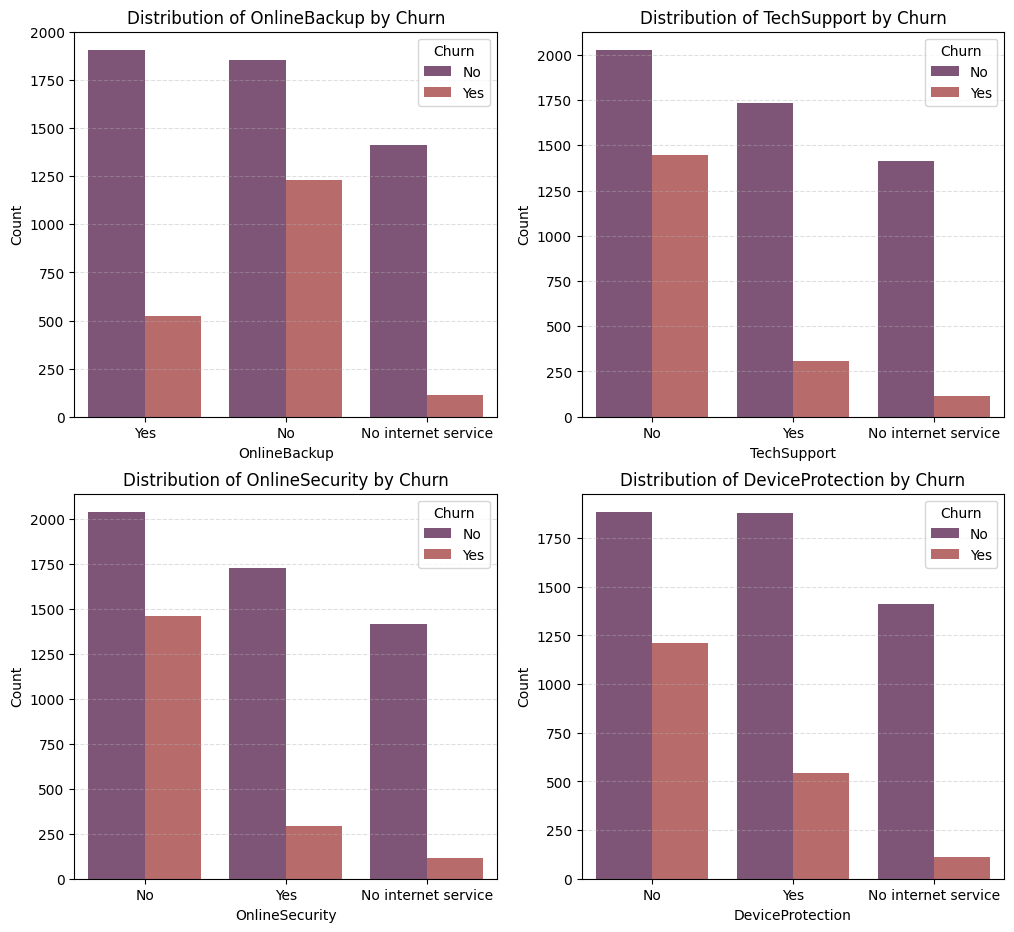

In [95]:
plt.figure(figsize=(12,11))

plt.subplot(2,2,1)
sns.countplot(df , x='OnlineBackup' , hue='Churn' , palette=["#864E7BD2", "#C55E5E"])
plt.title('Distribution of OnlineBackup by Churn')
plt.xlabel('OnlineBackup')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show

plt.subplot(2,2,2)
sns.countplot(df , x='TechSupport', hue='Churn' , palette=["#864E7BD2", "#C55E5E"])
plt.title('Distribution of TechSupport by Churn')
plt.xlabel('TechSupport')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show

plt.subplot(2,2,3)
sns.countplot(df , x='OnlineSecurity' , hue='Churn', palette=["#864E7BD2", "#C55E5E"])
plt.title('Distribution of OnlineSecurity by Churn')
plt.xlabel('OnlineSecurity')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show

plt.subplot(2,2,4)
sns.countplot(df , x='DeviceProtection' , hue='Churn' , palette=["#864E7BD2", "#C55E5E"])
plt.title('Distribution of DeviceProtection by Churn')
plt.xlabel('DeviceProtection')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show

Key Insights
- OnlineBackup: Customers without online backup show a higher churn count than customers with it.
- TechSupport: Churn counts are considerably higher among customers without tech support.
- OnlineSecurity: Customers without online security account for the largest churn count.
- DeviceProtection: Customers without device protection also show a higher churn count.
- No internet service: This group has relatively low churn counts across all four services.

Across all four services, customers who do not subscribe to additional services contribute more to the churn count. Online Security and Tech Support show particularly noticeable differences between customers who subscribe and those who do not.

In [96]:
services = [
    'OnlineBackup',
    'OnlineSecurity',
    'DeviceProtection',
    'TechSupport'
]

df['AdditionalServicesCount'] = (
    df[services] == 'Yes'
).sum(axis=1)

In [97]:
pd.crosstab(
    df['AdditionalServicesCount'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
AdditionalServicesCount,,
0,70.247046,29.752954
1,61.145194,38.854806
2,76.239067,23.760933
3,87.566419,12.433581
4,94.680851,5.319149


Observations:
1. Customers with zero additional services have a 29.56% churn rate.
2. Customers with one additional service show the highest churn rate of 38.85%.
3. Customers with two services have a lower churn rate of 23.76%.
4. Customers with three services have a churn rate of 12.43%.
5. Customers subscribed to all four services have the lowest churn rate of 5.32%.  

Overall conclusion:  
The results show that customers subscribing to more additional services generally have lower churn rates, particularly among those with three or four services.
This suggests that broader service adoption is associated with better customer retention.

#### **Q12: Does Internet Service type explain the difference in churn rates between customers with zero and one additional service?**

In [98]:
(df['AdditionalServicesCount']== 0).value_counts()

AdditionalServicesCount
False    4250
True     2793
Name: count, dtype: int64

In [99]:
pd.crosstab((df['AdditionalServicesCount']== 0), df['Churn'], normalize='index')*100

Churn,No,Yes
AdditionalServicesCount,,
False,75.576471,24.423529
True,70.247046,29.752954


In [100]:
(df['AdditionalServicesCount']== 1).value_counts()

AdditionalServicesCount
False    5576
True     1467
Name: count, dtype: int64

In [101]:
pd.crosstab((df['AdditionalServicesCount']== 1), df['Churn'] , normalize='index') * 100

Churn,No,Yes
AdditionalServicesCount,,
False,76.703730,23.296270
True,61.145194,38.854806


In [102]:
subset = df[df['AdditionalServicesCount'].isin([0, 1])]

pd.crosstab([subset['AdditionalServicesCount'],subset['InternetService']],subset['Churn'],normalize='index').mul(100).round(2)

Churn                                       No    Yes
AdditionalServicesCount InternetService              
0                       DSL              57.28  42.72
                        Fiber optic      36.44  63.56
                        No               92.60   7.40
1                       DSL              73.36  26.64
                        Fiber optic      53.21  46.79

The analysis reveals an interesting pattern:
- Among customers with zero additional services, Fiber Optic users have the highest churn rate of 63.30%, followed by DSL users at 42.45%.
- Customers with no internet service have a significantly lower churn rate of only 7.21%.
- Among customers with one additional service, Fiber Optic users have a churn rate of 46.79%, while DSL users have a churn rate of 26.64%.
- Interestingly, within both DSL and Fiber Optic categories, customers with one additional service have lower churn rates than those with zero additional services.
  
Key Finding  
The overall churn rate for customers with zero additional services is lower partly because this group includes customers who do not have internet service at all. Their very low churn rate of 7.21% pulls down the overall average.


#### **Q13: Does subscribing to Streaming TV or Streaming Movies have any relationship with customer retention?**

In [103]:
df['StreamingTV'].value_counts()

StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

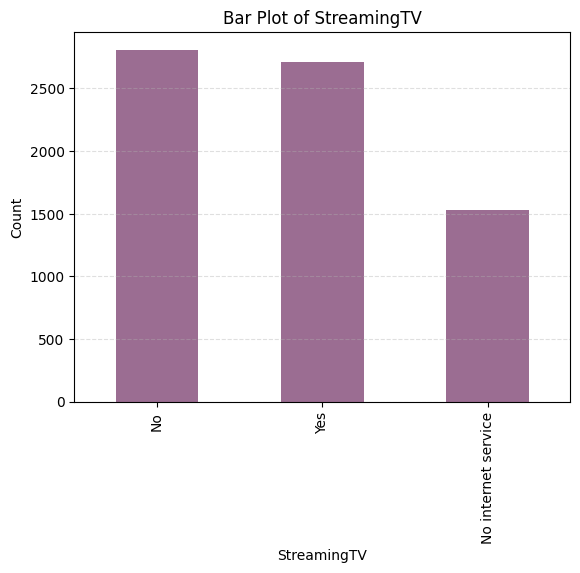

In [104]:
df['StreamingTV'].value_counts().plot(kind='bar' , color="#864E7BD2")
plt.title('Bar Plot of StreamingTV')
plt.xlabel('StreamingTV')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show

In [105]:
pd.crosstab(df['StreamingTV'] , df['Churn'], normalize='index')*100

Churn,No,Yes
StreamingTV,,
No,66.476868,33.523132
No internet service,92.595020,7.404980
Yes,69.929812,30.070188


In [106]:
df['StreamingMovies'].value_counts()

StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

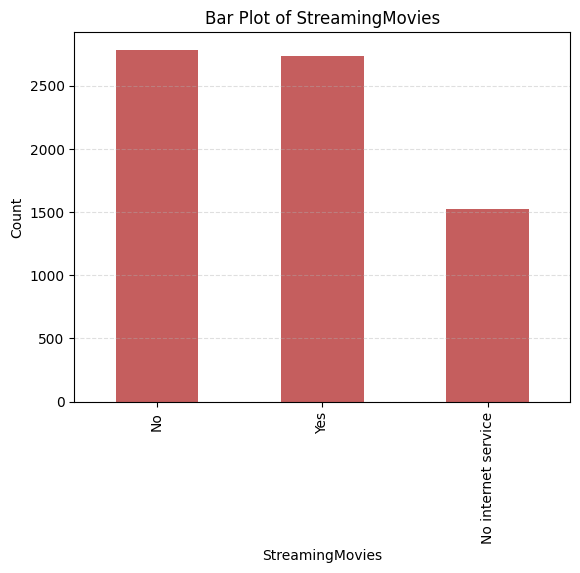

In [107]:
df['StreamingMovies'].value_counts().plot(kind='bar' , color= '#C55E5E')
plt.title('Bar Plot of StreamingMovies')
plt.xlabel('StreamingMovies')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show

In [108]:
pd.crosstab(df['StreamingMovies'] , df['Churn'], normalize='index')*100

Churn,No,Yes
StreamingMovies,,
No,66.319569,33.680431
No internet service,92.595020,7.404980
Yes,70.058565,29.941435


<function matplotlib.pyplot.show(close=None, block=None)>

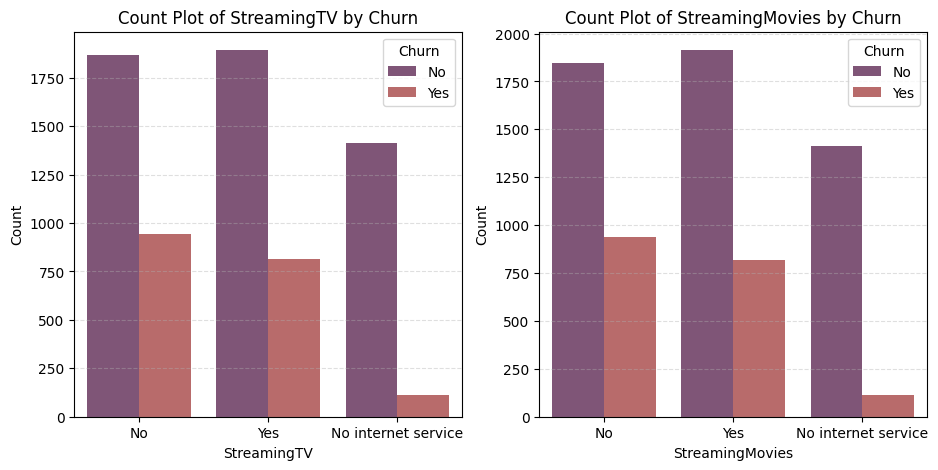

In [109]:
plt.figure(figsize=(11,5))

plt.subplot(1,2,1)
sns.countplot(df , x='StreamingTV' , hue='Churn' , palette=["#864E7BD2", "#C55E5E"])
plt.title('Count Plot of StreamingTV by Churn')
plt.xlabel('StreamingTV')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show

plt.subplot(1,2,2)
sns.countplot(df , x='StreamingMovies', hue='Churn' , palette=["#864E7BD2", "#C55E5E"])
plt.title('Count Plot of StreamingMovies by Churn')
plt.xlabel('StreamingMovies')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show

1. Streaming TV:  
2707 are using Streaming TV service and in 2707 , 1893 are not churn and 814 are churn. Those who are not using this Service are 2810 , among 2810 ,1868 are not churn and 942 are churn. While those who are not availing services are 1526 in total in which 1413 are not churn and 113 are churn.
2. Streaming Movies:  
2732 are those who are availing the service while 2785 are not and those who has No internet Service are 1526 in total . Those who are using the service in them 1914 are not churn and 818 are churn and in those who are not using this service 1847 are not churn and 938 are churn . While on the other hand those who are not availing internet service in those 1413 are not churn and 113 are churn.  

Customers subscribing to streaming services have slightly lower churn rates than those not subscribing, among the relevant internet-service groups. The difference is relatively small.

#### **Q14: Which payment methods are associated with higher customer churn?**

In [110]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

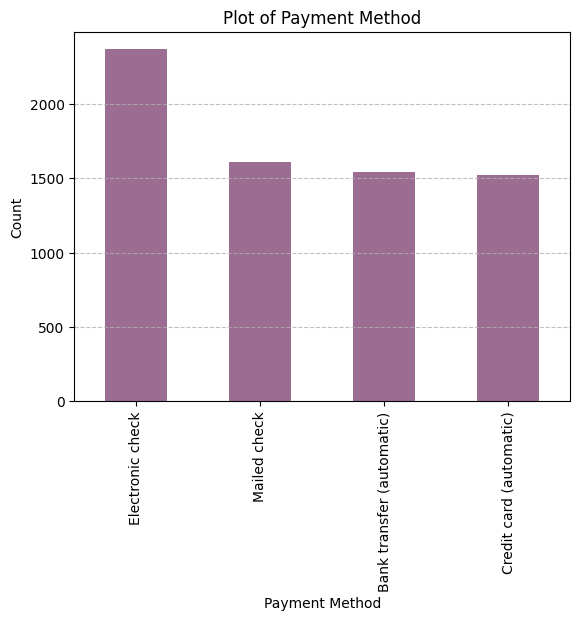

In [111]:
df['PaymentMethod'].value_counts().plot(kind='bar' , color="#864E7BD2")
plt.title('Plot of Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.8)
plt.show


In [112]:
pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


<function matplotlib.pyplot.show(close=None, block=None)>

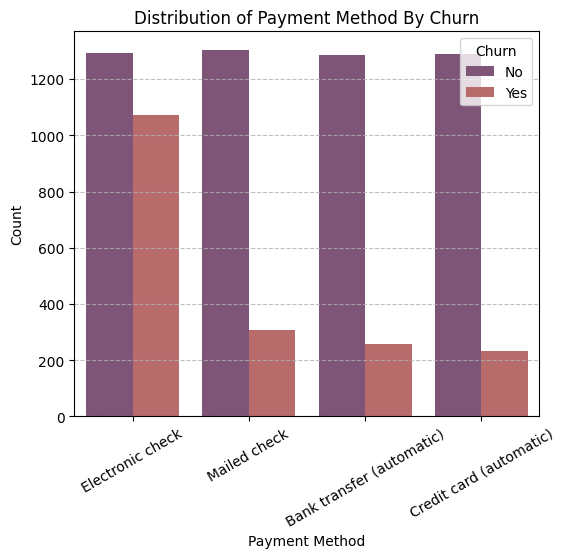

In [113]:
plt.figure(figsize=(6,5))
sns.countplot(df, x='PaymentMethod', hue='Churn' , palette=["#864E7BD2", "#C55E5E"])
plt.title('Distribution of Payment Method By Churn')
plt.xlabel('Payment Method')
plt.ylabel('Count')
plt.xticks(rotation = 30)
plt.grid(axis='y' , linestyle='--' , alpha = 0.8)
plt.show

Key Insights
- Electronic Check: Has the highest churn count by a significant margin.
- Mailed Check: Shows considerably fewer churned customers.
- Bank Transfer (Automatic): Has a relatively low churn count.
- Credit Card (Automatic): Also shows a relatively low churn count.
- Retained customer counts are fairly similar across all four payment methods.

#### **Q15: Are expensive monthly plans associated with higher churn?**

In [114]:
df['ChargeGroup'] = pd.qcut(df['MonthlyCharges'], q=4)

In [115]:
pd.crosstab(df['ChargeGroup'],df['Churn'],normalize='index').mul(100).round(2)


Churn,No,Yes
ChargeGroup,,
"(18.249, 35.5]",88.76,11.24
"(35.5, 70.35]",75.42,24.58
"(70.35, 89.85]",62.49,37.51
"(89.85, 118.75]",67.12,32.88


Churn generally increases as monthly charges rise from Q1 to Q3. However, Q4 does not follow this pattern, as its churn rate decreases from 37.36% to 32.91%.

This suggests that customers paying higher monthly charges may be more likely to churn, but the relationship is not strictly linear.

In [116]:
pd.crosstab([df['ChargeGroup'],df['Contract']],df['Churn'],normalize='index').mul(100).round(2)

Churn                              No    Yes
ChargeGroup     Contract                    
(18.249, 35.5]  Month-to-month  74.97  25.03
                One year        96.95   3.05
                Two year        99.22   0.78
(35.5, 70.35]   Month-to-month  64.38  35.62
                One year        91.37   8.63
                Two year        97.55   2.45
(70.35, 89.85]  Month-to-month  46.72  53.28
                One year        88.93  11.07
                Two year        98.45   1.55
(89.85, 118.75] Month-to-month  47.82  52.18
                One year        79.15  20.85
                Two year        92.99   7.01

The analysis reveals that the relationship between monthly charges and customer churn varies across contract types. Month-to-month customers demonstrate the highest churn rates across all monthly charge groups, reaching 53.12% in the upper-middle charge category. One-year contract customers also show increasing churn as monthly charges rise, while two-year contract customers maintain relatively low churn rates throughout. These findings suggest that higher monthly charges are associated with increased churn, but contract type plays an important role in customer retention. In particular, longer-term contracts are associated with substantially stronger retention, even among customers paying higher monthly charges.


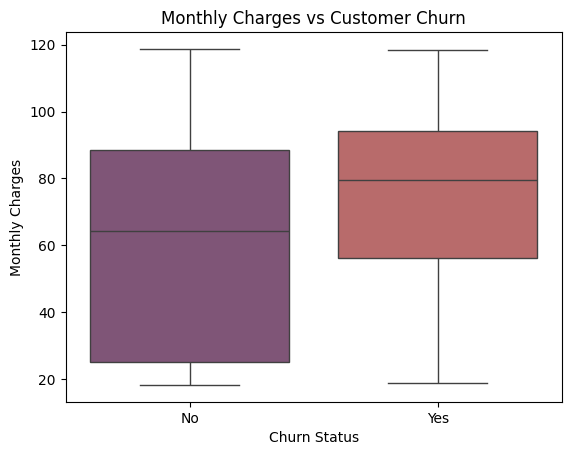

In [117]:
sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges',
    palette=["#864E7BD2", "#C55E5E"]
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')
plt.show()

In [118]:
pd.crosstab([df['PaymentMethod'], df['ChargeGroup']] , df['Churn'], normalize='index') *100

Churn                                             No        Yes
PaymentMethod             ChargeGroup                          
Bank transfer (automatic) (18.249, 35.5]   92.370572   7.629428
                          (35.5, 70.35]    86.720867  13.279133
                          (70.35, 89.85]   78.723404  21.276596
                          (89.85, 118.75]  76.620370  23.379630
Credit card (automatic)   (18.249, 35.5]   95.148248   4.851752
                          (35.5, 70.35]    84.702550  15.297450
                          (70.35, 89.85]   80.423280  19.576720
                          (89.85, 118.75]  79.523810  20.476190
Electronic check          (18.249, 35.5]   70.297030  29.702970
                          (35.5, 70.35]    62.110727  37.889273
                          (70.35, 89.85]   45.000000  55.000000
                          (89.85, 118.75]  54.906832  45.093168
Mailed check              (18.249, 35.5]   88.807786  11.192214
                          (35.5, 70.35]    75.965665  24.034335
                          (70.35, 89.85]   65.919283  34.080717
                          (89.85, 118.75]  72.277228  27.722772

Key Findings
1. Electronic Check users consistently show higher churn rates than users of other payment methods within the same charge groups.
2. Automatic payment methods show comparatively lower churn rates.
3. Churn generally increases with monthly charges, although the highest charge group does not always have the highest churn.

Conclusion: Payment method appears to be an important factor associated with customer churn. Electronic Check users demonstrate particularly high churn rates, especially among customers paying upper-middle monthly charges. Customers using automatic payment methods show comparatively stronger retention.

#### **Q16: Are customers enrolled in paperless billing more likely to churn than customers receiving traditional bills?**

In [119]:
df['PaperlessBilling'].value_counts()

PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

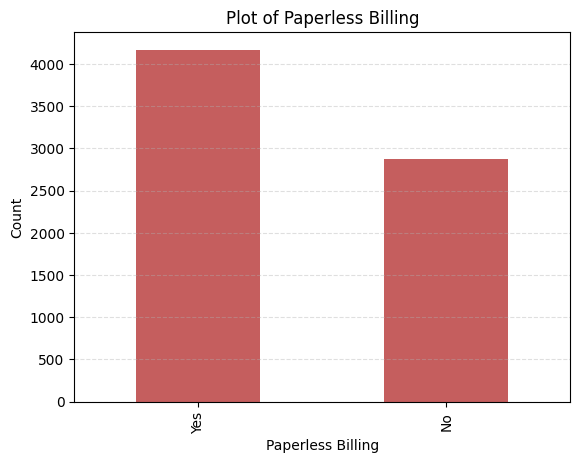

In [120]:
df['PaperlessBilling'].value_counts().plot(kind='bar' , color="#C55E5E")
plt.title('Plot of Paperless Billing')
plt.xlabel('Paperless Billing')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show

In [121]:
pd.crosstab(df['PaperlessBilling'] , df['Churn'], normalize='index')*100

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


<function matplotlib.pyplot.show(close=None, block=None)>

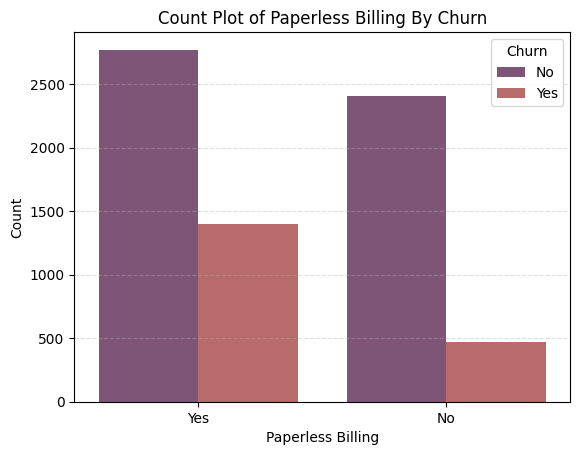

In [122]:
sns.countplot(df , x='PaperlessBilling' , hue= 'Churn' ,  palette=["#864E7BD2", "#C55E5E"])
plt.title('Count Plot of Paperless Billing By Churn')
plt.xlabel('Paperless Billing')
plt.ylabel('Count')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show

In the given chart we an clearly see that those who are getting paperless billing are around 4171 and in them 2771 are not churn and 1400 are churn , and those who are not recieving any paperless billing are 2872 and in them there are 2403 are not churn and 469 are churn . 

In [123]:
pd.crosstab([df['PaperlessBilling'] , df['Contract']], df['Churn'], normalize='index')*100

Churn                                   No        Yes
PaperlessBilling Contract                            
No               Month-to-month  68.502715  31.497285
                 One year        92.867756   7.132244
                 Two year        98.351648   1.648352
Yes              Month-to-month  51.701469  48.298531
                 One year        85.250000  14.750000
                 Two year        95.796178   4.203822

In [124]:
pd.crosstab([df['PaperlessBilling'] , df['PaymentMethod']], df['Churn'], normalize='index')*100

Churn                                              No        Yes
PaperlessBilling PaymentMethod                                  
No               Bank transfer (automatic)  88.973966  11.026034
                 Credit card (automatic)    90.000000  10.000000
                 Electronic check           67.255217  32.744783
                 Mailed check               86.506276  13.493724
Yes              Bank transfer (automatic)  79.124579  20.875421
                 Credit card (automatic)    80.952381  19.047619
                 Electronic check           50.229621  49.770379
                 Mailed check               72.713415  27.286585

Both analyses reveal a consistent relationship between paperless billing and customer churn. Paperless billing customers demonstrate higher churn rates regardless of their contract type or payment method. Furthermore, month-to-month contracts and electronic check payments represent particularly high-churn segments.

These findings suggest that the company should investigate the experiences of paperless billing customers, especially those using electronic checks and month-to-month contracts.

#### **Q17: How does customer tenure relate to the likelihood of churn?**

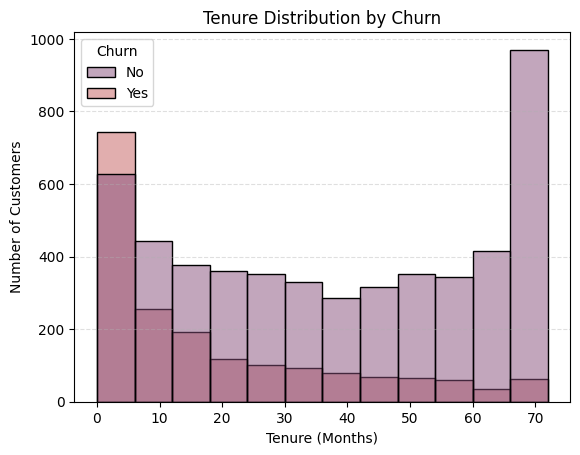

In [125]:
sns.histplot(data=df, x='tenure', bins=12, hue='Churn', palette=["#864E7BD2", "#C55E5E"])

plt.title('Tenure Distribution by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show()

Customers with shorter tenure are more likely to churn, whereas long-term customers tend to stay with the company. This suggests that customer loyalty increases with longer tenure.

In [126]:
pd.crosstab(pd.cut(df['tenure'], bins=[-1, 12, 24, 36, 48, 60, 72]),df['Churn'],normalize='index') * 100

Churn,No,Yes
tenure,,
"(-1, 12]",52.561757,47.438243
"(12, 24]",71.289062,28.710938
"(24, 36]",78.365385,21.634615
"(36, 48]",80.971129,19.028871
"(48, 60]",85.576923,14.423077
"(60, 72]",93.390192,6.609808


Customers are considerably more likely to leave during their early relationship with the telecom company. As tenure increases, the proportion of customers leaving decreases.  
This suggests that the company should pay particular attention to customer retention during the first year.

#### **Q18: Are customers with higher monthly charges more likely to churn?**

In [127]:
df.groupby('Churn')['MonthlyCharges'].agg(
    ['mean', 'median', 'min', 'max'])

,mean,median,min,max
Churn,,,,
No,61.265124,64.425,18.25,118.75
Yes,74.441332,79.650,18.85,118.35


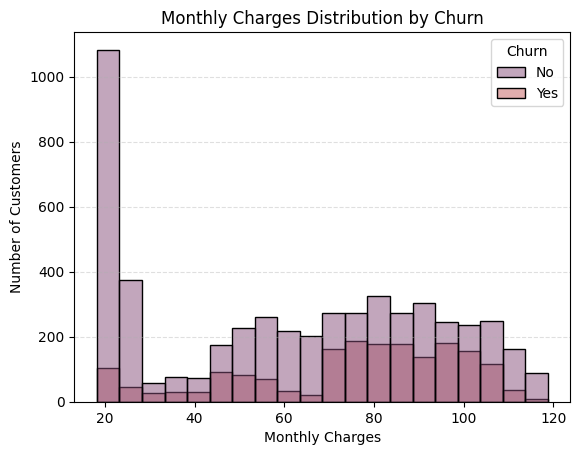

In [128]:
sns.histplot(df , x='MonthlyCharges' ,bins=20, hue='Churn' , palette=["#864E7BD2", "#C55E5E"] )
plt.title('Monthly Charges Distribution by Churn')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show()

The analysis shows that churn generally increases as monthly charges rise across the lower and middle charge groups. However, the highest charge group does not follow this pattern, as its churn rate decreases from 37.36% to 32.91%. This suggests that higher monthly charges are associated with increased churn in certain customer groups, but the relationship is not strictly linear. Contract type also plays an important role in this relationship.

#### **Q19: How do accumulated customer charges differ between retained and churned customers, and how does tenure affect this relationship?**

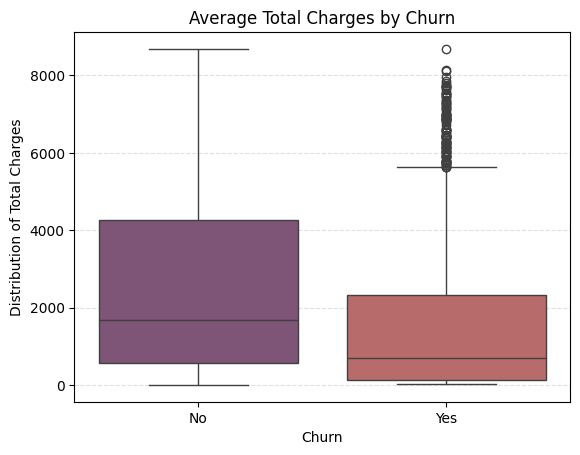

In [129]:
sns.boxplot(data=df, x='Churn', y='TotalCharges', hue='Churn', palette=["#864E7BD2", "#C55E5E"])

plt.title('Average Total Charges by Churn')
plt.xlabel('Churn')
plt.ylabel('Distribution of Total Charges')
plt.grid(axis='y' , linestyle='--' , alpha = 0.4)
plt.show()

In [130]:
df.groupby('Churn')['TotalCharges'].agg(
    ['mean', 'median', 'min', 'max']
)

,mean,median,min,max
Churn,,,,
No,2549.911442,1679.525,0.00,8672.45
Yes,1531.796094,703.550,18.85,8684.80


Both the box plot and statistical summary show that customers who stayed with the company have higher TotalCharges (mean: 2559.67, median: 1698.85) than customers who churned (mean: 1541.38, median: 713.10). This suggests that churned customers generally accumulated fewer charges, possibly because they left earlier. TotalCharges is therefore closely related to customer tenure.

#### **Q20: Which numerical features show the strongest association with customer churn?**


In [131]:
df['ChurnEncoded'] = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

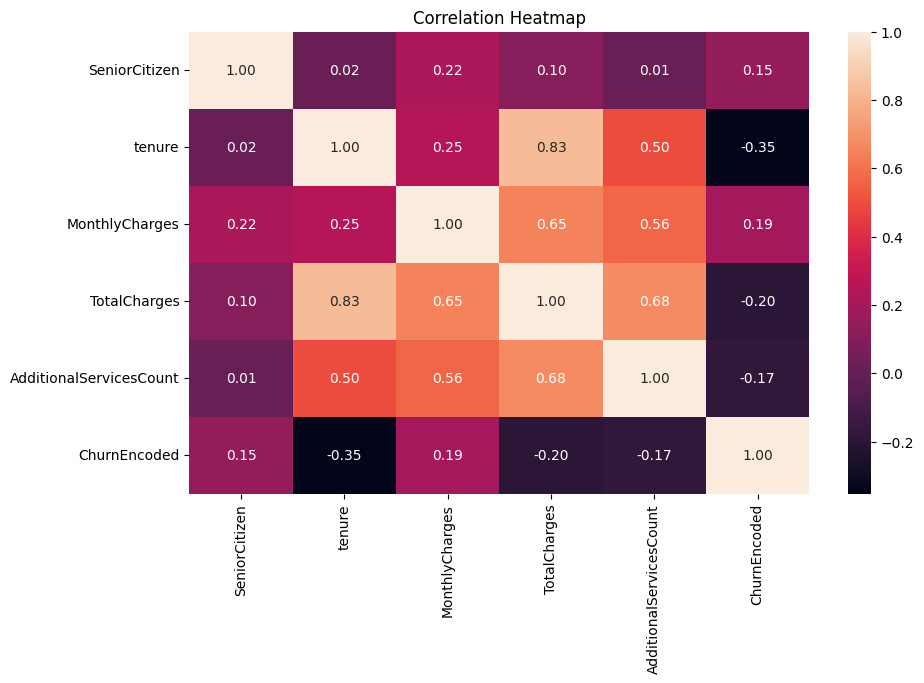

In [132]:
plt.figure(figsize=(10, 6))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

Tenure has the strongest correlation with churn among the numerical features. Most other relationships are weak, meaning churn is likely influenced by multiple factors rather than one numerical variable.

#### **Q21: How many Churn Customers are there?**

In [133]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

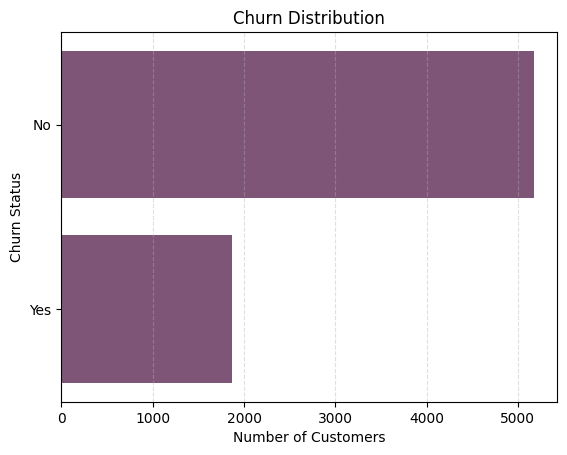

In [134]:
sns.countplot(df['Churn'] , palette=["#864E7BD2"])
plt.title('Churn Distribution')
plt.ylabel('Churn Status')
plt.xlabel('Number of Customers')
plt.grid(axis='x' , linestyle='--' , alpha = 0.4)
plt.show()


- Retained Customers (No): 5,164 (73.55%)
- Churned Customers (Yes): 1,857 (26.45%)

Approximately 73.55% of customers stayed with the company, while 26.45% discontinued its services. This indicates that around one in four customers churned, highlighting a need for effective customer-retention strategies.

#### **Q22: How is contract type associated with customer churn?**

In [135]:
pd.crosstab((df['Contract']=='Month-to-month'), df['Churn'], normalize='index')* 100

Churn,No,Yes
Contract,,
False,93.244949,6.755051
True,57.290323,42.709677


In [136]:
pd.crosstab((df['Contract']=='One year'), df['Churn'], normalize='index')* 100

Churn,No,Yes
Contract,,
False,69.425494,30.574506
True,88.730482,11.269518


In [137]:
pd.crosstab((df['Contract']=='Two year'), df['Churn'], normalize='index')* 100

Churn,No,Yes
Contract,,
False,65.949888,34.050112
True,97.168142,2.831858


Month-to-month customers have the highest churn rate of 42.64%, followed by one-year contract customers at 11.26%. Two-year contract customers have the lowest churn rate of only 2.83%.

Conclusion: Customers with shorter contract commitments are considerably more likely to churn, whereas customers with longer-term contracts demonstrate stronger retention.

In [138]:
pd.crosstab([df['Contract'] ,df['AdditionalServicesCount']] , df['Churn'], normalize='index')* 100

Churn                                          No        Yes
Contract       AdditionalServicesCount                      
Month-to-month 0                        53.503185  46.496815
               1                        54.830508  45.169492
               2                        63.507779  36.492221
               3                        77.092511  22.907489
               4                        73.529412  26.470588
One year       0                        94.774347   5.225653
               1                        84.331797  15.668203
               2                        88.154897  11.845103
               3                        84.039088  15.960912
               4                        89.887640  10.112360
Two year       0                        99.069767   0.930233
               1                        95.714286   4.285714
               2                        92.920354   7.079646
               3                        96.068796   3.931204
               4                        97.982709   2.017291

Month-to-month customers generally show higher churn counts across service groups. Within this contract category, customers with zero or one additional service have particularly high churn rates.

In [139]:
pd.crosstab([df['Contract'] ,df['Dependents']] , df['Churn'] , normalize='index')*100

Churn                             No        Yes
Contract       Dependents                      
Month-to-month No          54.763448  45.236552
               Yes         67.173638  32.826362
One year       No          87.579618  12.420382
               Yes         90.772128   9.227872
Two year       No          96.685083   3.314917
               Yes         97.721519   2.278481

Across all three contract categories, customers without dependents have higher churn rates than customers with dependents.

The difference is particularly noticeable among month-to-month customers.

Conclusion: Family status may also be associated with customer retention, even when customers are grouped by contract type.

In [140]:
pd.crosstab([df['Contract'] ,df['Partner']] , df['Churn'] , normalize='index')*100

Churn                          No        Yes
Contract       Partner                      
Month-to-month No       55.310621  44.689379
               Yes      60.869565  39.130435
One year       No       89.424572  10.575428
               Yes      88.192771  11.807229
Two year       No       96.620278   3.379722
               Yes      97.399329   2.600671

The relationship between partner status and churn varies across contract types.
- For month-to-month contracts, customers without partners have higher churn.
- For one-year contracts, customers with partners have slightly higher churn.
- For two-year contracts, customers without partners have slightly higher churn.  

Key Insight: Partner status appears to have a more noticeable association with churn among month-to-month customers, whereas the differences are relatively small among one-year and two-year contract customers.

In [141]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [142]:
pd.crosstab([df['Contract'] ,df['PaymentMethod']] , df['Churn'] , normalize='index')*100

Churn                                            No        Yes
Contract       PaymentMethod                                  
Month-to-month Bank transfer (automatic)  65.874363  34.125637
               Credit card (automatic)    67.219153  32.780847
               Electronic check           46.270270  53.729730
               Mailed check               68.421053  31.578947
One year       Bank transfer (automatic)  90.281330   9.718670
               Credit card (automatic)    89.698492  10.301508
               Electronic check           81.556196  18.443804
               Mailed check               93.175074   6.824926
Two year       Bank transfer (automatic)  96.631206   3.368794
               Credit card (automatic)    97.762478   2.237522
               Electronic check           92.261905   7.738095
               Mailed check               99.214660   0.785340

Key Findings
1. Month-to-month customers have the highest churn rates across all four payment methods.
2. Electronic Check users show the highest churn rate within every contract category.
3. Two-year contract customers demonstrate the lowest churn rates across all payment methods.
4. Even among two-year contract customers, Electronic Check users have higher churn (7.74%) than customers using automatic payments.\

Conclusion: The analysis reveals that both contract type and payment method are associated with customer churn. Electronic Check users consistently demonstrate higher churn rates, while longer-term contracts are associated with stronger customer retention. The combination of month-to-month contracts and Electronic Check usage shows the highest churn rate at 53.58%.

#### **Q23: How does customer churn vary between customers who subscribe to Phone Service and those who do not?**

In [143]:
pd.crosstab(df['PhoneService'] , df['Churn'] , normalize='index') * 100

Churn,No,Yes
PhoneService,,
No,75.073314,24.926686
Yes,73.290363,26.709637


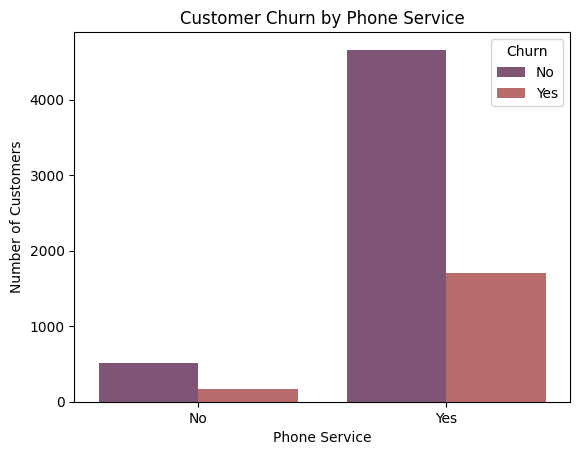

In [144]:
sns.countplot(data=df, x='PhoneService', hue='Churn' , palette=["#864E7BD2", "#C55E5E"])
plt.title('Customer Churn by Phone Service')
plt.xlabel('Phone Service')
plt.ylabel('Number of Customers')
plt.show()

The churn rates of customers with and without Phone Service are quite similar. Customers using Phone Service show a slightly higher churn rate (26.71%) compared to those without it (24.93%). This suggests that Phone Service alone does not have a strong relationship with customer churn.

# **Final Answer to the Main Research Question**

## Main Research Question

**What factors are associated with customer churn in the telecommunications industry, and how can these factors help identify high-risk customers and improve customer retention?**

## 1. Factors Associated with Customer Churn

Based on the Exploratory Data Analysis (EDA), several customer characteristics and service-related factors were found to be associated with customer churn.

| Factor | Key Finding |
|---|---|
| **Contract Type** | Month-to-month customers have the highest churn rate (42.65%), compared with one-year (11.28%) and two-year contracts (2.83%). |
| **Customer Tenure** | Customers within their first 12 months show the highest churn tendency, indicating greater vulnerability among newer customers. |
| **Additional Services** | Customers without Online Backup, Online Security, Device Protection, and Tech Support generally have higher churn rates. |
| **Senior Citizens** | Senior citizens have a churn rate of 41.63%, compared with 23.50% for non-senior customers. |
| **Dependents** | Customers without dependents generally demonstrate higher churn across service, contract, internet, and tenure comparisons. |
| **Internet Service** | Fiber Optic users have the highest churn rate (41.89%), followed by DSL users (18.96%) and customers without internet service (7.40%). |
| **Payment Method** | Electronic Check users demonstrate the highest churn rate among payment methods. |
| **Paperless Billing** | Customers using paperless billing have a higher churn rate (33.56%) than those without it (16.33%). |
| **Monthly Charges** | Churn generally increases across monthly-charge groups up to the third quartile, but decreases in the highest charge group. |
| **Total Charges** | Churned customers have lower mean and median TotalCharges than retained customers, potentially reflecting shorter customer tenure. |
| **Partner Status** | Customers without partners generally show higher churn across services and internet categories, although the relationship varies across contract types. |
| **Multiple Lines** | Churn rates are relatively similar among customers with and without multiple lines. |
| **Gender** | Male and female customers show broadly similar churn patterns, indicating no major difference based on gender. |
| **Streaming Services** | Streaming TV and Movies show comparatively smaller differences in churn than some other service-related factors. |

## 2. Deeper Insights: Combined Customer Segments

Further analysis of multiple variables revealed combinations of customer characteristics associated with particularly high churn rates.

| Customer Segment | Churn Rate |
|---|---:|
| Senior Citizens + First 12 Months | 67.71% |
| Month-to-month + Electronic Check | 53.58% |
| Senior Citizens + Month-to-month | 54.59% |
| Senior Citizens + Electronic Check | 53.29% |
| Month-to-month + Third Monthly Charge Quartile | 53.12% |
| Senior Citizens + No Online Backup | 52.69% |
| Senior Citizens + No Tech Support | 50.54% |
| Senior Citizens + No Online Security | 50.31% |
| Fiber Optic + Electronic Check | 53.08% |
| Fiber Optic + Month-to-month | 54.48% |
| Month-to-month + Zero Additional Services | 46.39% |

These combinations highlight that churn risk is not limited to one particular characteristic. Instead, several customer attributes and service choices may overlap within high-churn segments.

## 3. Overall Customer Churn Distribution

Out of **7,021 customers**:

- **Retained Customers:** 5,164 (73.55%)
- **Churned Customers:** 1,857 (26.45%)

Approximately one in four customers discontinued the company's services, demonstrating the importance of understanding customer behavior and retention patterns.

## 4. Final Conclusion

The EDA reveals that customer churn is associated with multiple demographic, financial, contractual, and service-related factors. The most noticeable patterns are found among month-to-month customers, senior citizens, customers with shorter tenure, customers without dependents, Fiber Optic users, and Electronic Check users.

The combined analysis further highlights particularly vulnerable segments, including senior citizens within their first year, senior citizens using month-to-month contracts, and customers combining month-to-month contracts with Electronic Check payments.

Additionally, the absence of Online Security, Online Backup, Device Protection, and Tech Support is generally associated with higher churn rates.

These findings suggest that the company should pay particular attention to newer customers, review its month-to-month customer-retention strategies, investigate the concerns of Fiber Optic and Electronic Check users, and evaluate the value of its additional services.

Overall, this analysis provides a clearer understanding of customer churn patterns and identifies customer segments that deserve further investigation and targeted retention efforts. However, these relationships represent statistical associations rather than proven causes of customer churn.


# ***Model Development***

In [145]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn', 'AdditionalServicesCount',
       'ChargeGroup', 'ChurnEncoded'],
      dtype='object')

#### **Feature Engineering**

In [146]:
df['StreamingServices'] = df.apply(lambda row:
                                   'Both' if row['StreamingTV']=='Yes' and row['StreamingMovies']== 'Yes'
                                   else 'TV only' if row['StreamingTV']=='Yes'
                                   else 'Movie only' if row['StreamingMovies']== 'Yes'
                                   else 'Neither', 
                                   axis = 1)

In [147]:
df['StreamingServices'].value_counts()

StreamingServices
Neither       3544
Both          1940
Movie only     792
TV only        767
Name: count, dtype: int64

#### **Dropping Unnecessary Columns**

In [148]:
df.drop(columns=['MultipleLines' , 'StreamingTV' , 'StreamingMovies' , 'ChargeGroup','PhoneService' , 'Churn'] , axis=1 , inplace=True)

In [149]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'AdditionalServicesCount',
       'ChurnEncoded', 'StreamingServices'],
      dtype='object')

#### **Training the model**

In [150]:
from sklearn.model_selection import train_test_split
X = df.drop('ChurnEncoded', axis=1)
y = df['ChurnEncoded']

In [151]:
X_train , X_test , y_train , y_test = train_test_split(X, y , random_state=42 , test_size=0.2)

In [152]:
X_train.shape , X_test.shape

((5634, 17), (1409, 17))

In [153]:
categorical_cols = [
    'gender',
    'InternetService',
    'Partner',
    'Dependents',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'Contract',
    'PaperlessBilling',
    'PaymentMethod',
    'StreamingServices'
]

numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

#### **Applying One hot Encoding & Standard Scalar**

In [154]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder , StandardScaler


p1 = ColumnTransformer(transformers=[
    ('encoded' , OneHotEncoder(handle_unknown='ignore') , categorical_cols),
    ('scaled' , StandardScaler() , numerical_cols)
] , remainder= 'passthrough')

#### **Algorithm**

In [155]:
X_train_encoded = p1.fit_transform(X_train)
X_test_encoded = p1.transform(X_test)

##### 1. ***Random Forest***

In [156]:
from sklearn.ensemble import RandomForestClassifier
rf= RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    random_state=42
)

##### **Creating Pipeline**

In [157]:
from sklearn.pipeline import Pipeline
pipe_1 = Pipeline([
    ('p1' , p1),
    ('rf' , rf)
])
pipe_1.fit(X_train , y_train)


,steps,"[('p1', ...), ('rf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('encoded', ...), ('scaled', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [158]:
y_pred_1 = pipe_1.predict(X_test)
y_pred_1

array([1, 0, 0, ..., 0, 0, 0], shape=(1409,))

In [159]:
from sklearn.metrics import accuracy_score , classification_report
Acc= accuracy_score(y_pred_1, y_test)
report = classification_report(y_pred_1 , y_test)
print(report)
print(f'Accuracy: {Acc}')

              precision    recall  f1-score   support

           0       0.92      0.84      0.88      1135
           1       0.51      0.69      0.59       274

    accuracy                           0.81      1409
   macro avg       0.71      0.77      0.73      1409
weighted avg       0.84      0.81      0.82      1409

Accuracy: 0.8105039034776437


#### **Applying Grid Search CV**

In [160]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    }

In [161]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    rf,
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=1,
    verbose=1
)
grid.fit(X_train_encoded , y_train)

Fitting 3 folds for each of 81 candidates, totalling 243 fits


,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [5, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,scoring,'f1'
,n_jobs,1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [162]:
print(grid.best_params_)
print(grid.best_score_)

{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
0.5761453478439352


In [163]:
grid_rf= grid.best_estimator_

In [164]:
from sklearn.metrics import f1_score
y_pred_rf_tuned = grid_rf.predict(X_test_encoded)

print(classification_report(y_test, y_pred_rf_tuned))
print("Accuracy:", accuracy_score(y_test, y_pred_rf_tuned))
print("F1 Score:", f1_score(y_test, y_pred_rf_tuned))

              precision    recall  f1-score   support

           0       0.84      0.92      0.88      1036
           1       0.69      0.52      0.60       373

    accuracy                           0.81      1409
   macro avg       0.77      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Accuracy: 0.8119233498935415
F1 Score: 0.5954198473282443


##### 2. ***Naive Bayes***

In [165]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()

In [166]:
from sklearn.pipeline import Pipeline
pipe_2 = Pipeline([
    ('p1' , p1),
    ('nb' , nb)
])
pipe_2.fit(X_train , y_train)

,steps,"[('p1', ...), ('nb', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('encoded', ...), ('scaled', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [167]:
y_pred_2 = pipe_2.predict(X_test)
y_pred_2

array([1, 0, 0, ..., 0, 0, 1], shape=(1409,))

In [168]:
from sklearn.metrics import accuracy_score , classification_report
Acc= accuracy_score( y_test, y_pred_2 )
report = classification_report( y_test ,y_pred_2 )
print(report)
print(f'Accuracy Score Naive Bayes: {Acc}')

              precision    recall  f1-score   support

           0       0.92      0.67      0.77      1036
           1       0.48      0.84      0.61       373

    accuracy                           0.71      1409
   macro avg       0.70      0.76      0.69      1409
weighted avg       0.80      0.71      0.73      1409

Accuracy Score Naive Bayes: 0.7139815471965933


##### 3. ***SVM***

In [169]:
from sklearn.svm import SVC
svm = SVC(kernel='linear', C=1, random_state=42)

In [170]:
from sklearn.pipeline import Pipeline
pipe_3 = Pipeline([
    ('p1' , p1),
    ('svm' , svm)
])
pipe_3.fit(X_train , y_train)

,steps,"[('p1', ...), ('svm', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('encoded', ...), ('scaled', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [171]:
y_pred_3 = pipe_3.predict(X_test)
y_pred_3

array([0, 0, 0, ..., 0, 0, 0], shape=(1409,))

In [172]:
from sklearn.metrics import accuracy_score , classification_report
Acc= accuracy_score( y_test ,y_pred_3 )
report = classification_report( y_test ,y_pred_3 )
print(report)
print(f'Accuracy score: {Acc}')

              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.67      0.58      0.62       373

    accuracy                           0.81      1409
   macro avg       0.76      0.74      0.75      1409
weighted avg       0.81      0.81      0.81      1409

Accuracy score: 0.8140525195173882


#### **Applying Grid Search CV**

In [173]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

In [174]:
grid_svm = GridSearchCV(
    svm,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_svm.fit(X_train_encoded, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,estimator,"SVC(C=1, kern...ndom_state=42)"
,param_grid,"{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,10


In [175]:
print("Best Parameters:", grid_svm.best_params_)
print("Best CV F1 Score:", grid_svm.best_score_)

Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV F1 Score: 0.5723021036920579


In [176]:
grid_svm= grid_svm.best_estimator_

In [177]:
from sklearn.metrics import f1_score
y_pred_svm_tuned = grid_svm.predict(X_test_encoded)

print(classification_report(y_test, y_pred_svm_tuned))
print("Accuracy:", accuracy_score(y_test, y_pred_svm_tuned))
print("F1 Score:", f1_score(y_test, y_pred_svm_tuned))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1036
           1       0.65      0.58      0.61       373

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Accuracy: 0.8055358410220014
F1 Score: 0.6118980169971672


4. #### ***Logistic Regression***

In [178]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr = LogisticRegression()

pipe_4 = Pipeline([
    ('p1' , p1),
    ('lr' , lr)
])
pipe_4.fit(X_train , y_train)

,steps,"[('p1', ...), ('lr', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('encoded', ...), ('scaled', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [179]:
y_pred_4 = pipe_4.predict(X_test)
y_pred_4

array([1, 0, 0, ..., 0, 0, 0], shape=(1409,))

In [180]:
Acc= accuracy_score(y_test , y_pred_4)
report = classification_report(y_test, y_pred_4)
print(report)
print(f'Accuracy score LR: {Acc}')

              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.78      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409

Accuracy score LR: 0.8218594748048261


##### ***Applying Grid Search CV***

In [181]:
lr = LogisticRegression(max_iter=1000, random_state=42)

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs'],
    'class_weight': [None, 'balanced']
}

In [182]:
grid_lr = GridSearchCV(
    lr,
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_lr.fit(X_train_encoded, y_train)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


,estimator,LogisticRegre...ndom_state=42)
,param_grid,"{'C': [0.01, 0.1, ...], 'class_weight': [None, 'balanced'], 'solver': ['liblinear', 'lbfgs']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [183]:
print("Best Parameters:", grid_lr.best_params_)
print("Best CV F1 Score:", grid_lr.best_score_)

Best Parameters: {'C': 10, 'class_weight': 'balanced', 'solver': 'liblinear'}
Best CV F1 Score: 0.6182798235667648


In [184]:
best_lr = grid_lr.best_estimator_

In [185]:
from sklearn.metrics import f1_score
y_pred_lr_tuned = best_lr.predict(X_test_encoded)

print(classification_report(y_test, y_pred_lr_tuned))
print("Accuracy:", accuracy_score(y_test, y_pred_lr_tuned))
print("F1 Score:", f1_score(y_test, y_pred_lr_tuned))

              precision    recall  f1-score   support

           0       0.92      0.72      0.81      1036
           1       0.52      0.83      0.64       373

    accuracy                           0.75      1409
   macro avg       0.72      0.78      0.72      1409
weighted avg       0.82      0.75      0.76      1409

Accuracy: 0.7501774308019872
F1 Score: 0.6386036960985626


In [186]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = {
    'Model': ['SVM', 'Random Forest', 'Original LR', 'Tuned LR'],

    'Accuracy': [
        accuracy_score(y_test, y_pred_svm_tuned),
        accuracy_score(y_test, y_pred_rf_tuned),
        accuracy_score(y_test, y_pred_4),
        accuracy_score(y_test, y_pred_lr_tuned)
    ],

    'Precision': [
        precision_score(y_test, y_pred_svm_tuned),
        precision_score(y_test, y_pred_rf_tuned),
        precision_score(y_test, y_pred_4),
        precision_score(y_test, y_pred_lr_tuned)
    ],

    'Recall': [
        recall_score(y_test, y_pred_svm_tuned),
        recall_score(y_test, y_pred_rf_tuned),
        recall_score(y_test, y_pred_4),
        recall_score(y_test, y_pred_lr_tuned)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_svm_tuned),
        f1_score(y_test, y_pred_rf_tuned),
        f1_score(y_test, y_pred_4),
        f1_score(y_test, y_pred_lr_tuned)
    ]
}

comparison_df = pd.DataFrame(results)

print(comparison_df.round(3))

           Model  Accuracy  Precision  Recall  F1 Score
0            SVM     0.806      0.649   0.579     0.612
1  Random Forest     0.812      0.691   0.523     0.595
2    Original LR     0.822      0.688   0.598     0.640
3       Tuned LR     0.750      0.517   0.834     0.639


### Model Performance Comparison

Four algorithms were evaluated for telecom customer churn prediction: Random Forest, Naive Bayes, Support Vector Machine (SVM), and Logistic Regression. Logistic Regression was evaluated in two versions (original and tuned with GridSearchCV), and Random Forest and SVM used their tuned versions.

| Model | Accuracy | Precision | Recall | F1 Score |
|---|---|---|---|---|
| SVM (tuned) | 0.806 | 0.649 | 0.579 | 0.612 |
| Random Forest (tuned) | 0.812 | 0.691 | 0.523 | 0.595 |
| Naive Bayes | 0.714 | 0.480 | 0.840 | 0.610 |
| Original Logistic Regression | 0.822 | 0.688 | 0.598 | 0.640 |
| Tuned Logistic Regression | 0.750 | 0.517 | 0.834 | 0.639 |

- **Original Logistic Regression** achieved the highest accuracy (82.19%) and the highest F1-score (0.640). Its F1-score is almost identical to Tuned Logistic Regression (0.639), so the two are effectively tied on balance.
- **Tuned Logistic Regression** and **Naive Bayes** achieved the highest recall (about 83-84%), identifying most actual churners. However, both have low precision (about 48-52%), meaning many customers are wrongly flagged as churners. Tuned Logistic Regression is the stronger of the two, with higher accuracy (75.0% vs 71.4%) and F1-score (0.639 vs 0.610).
- **Random Forest** had the highest precision (0.691) but the lowest recall (0.523), so it missed nearly half of the churners.
- **SVM** performed moderately across all metrics and did not outperform Logistic Regression.

Overall, Original Logistic Regression is the best-balanced model, while Tuned Logistic Regression is the better choice when the priority is catching as many churners as possible.

In [187]:
from sklearn.metrics import confusion_matrix
cm_lr = confusion_matrix(y_test, y_pred_4)
print(f'Original LR:\n{cm_lr}')

Original LR:
[[935 101]
 [150 223]]


In [188]:
from sklearn.metrics import confusion_matrix
cm_lr = confusion_matrix(y_test, y_pred_lr_tuned)
print(f'Tuned LR:\n{cm_lr}')

Tuned LR:
[[746 290]
 [ 62 311]]


### Confusion Matrix Analysis

The confusion matrices show the trade-off between the two Logistic Regression models.

| Model | Churners caught (TP) | Churners missed (FN) | False alarms (FP) |
|---|---|---|---|
| Original LR | 223 | 150 | 101 |
| Tuned LR | 311 | 62 | 290 |

Tuning with balanced class weights helped the model catch 88 more churners (311 vs 223) and cut missed churners from 150 to 62. The cost is 189 more false alarms (290 vs 101). Which model is better depends on the cost of losing a customer versus the cost of a retention offer sent to someone who would have stayed.

In [189]:
import pandas as pd

# Take one customer as input
new_customer = pd.DataFrame([{
    'gender': 'Female',
    'SeniorCitizen': 0,
    'Partner': 'Yes',
    'Dependents': 'No',
    'tenure': 12,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No',
    'OnlineBackup': 'Yes',
    'DeviceProtection': 'No',
    'TechSupport': 'No',
    'StreamingServices': 'Both',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 85.50,
    'TotalCharges': 1026.00,
    'AdditionalServicesCount' : 3
}])

# Predict churn (pipeline handles encoding + scaling + model)
prediction = pipe_4.predict(new_customer)
proba = pipe_4.predict_proba(new_customer)[0][1]

# Display result
if prediction[0] == 1:
    print(f"Customer is likely to Churn. (Churn probability: {proba:.1%})")
else:
    print(f"Customer is likely to Stay. (Churn probability: {proba:.1%})")

Customer is likely to Churn. (Churn probability: 71.8%)


### Conclusion

This project explored customer churn patterns in the telecommunications industry through Exploratory Data Analysis and machine learning.

The analysis revealed that contract type, tenure, internet service, payment method, and additional services were associated with customer churn. Month-to-month customers, new customers (first 12 months), senior citizens, Fiber Optic users, and Electronic Check users showed the highest churn rates.

Four algorithms were developed and evaluated: Random Forest, Naive Bayes, Support Vector Machine, and Logistic Regression (original and tuned). Original Logistic Regression achieved the best balanced performance, with the highest accuracy (82.19%) and F1-score (0.640). Tuned Logistic Regression reached nearly the same F1-score (0.639) and the highest recall (83.4%), detecting 311 of 373 churners, at the cost of more false positives.

Because the two models perform almost equally on F1, the final choice should depend on business goals: Original Logistic Regression when retention offers are costly, and Tuned Logistic Regression when losing a customer is more costly than a wasted offer.

These findings show how data analysis and machine learning can support customer retention strategies. The relationships found are statistical associations, not proven causes of churn.

In [190]:
import joblib
joblib.dump(pipe_4, 'churn_model.pkl')

['churn_model.pkl']